# Assignment Beta — Question 2
## Parameter-Efficient Fine-Tuning for E-commerce Function Calling

**Student ID:** 23K0069  
**Course:** AI4015 — Agentic AI, Fall 2026  
**Base model:** `Qwen/Qwen2.5-1.5B-Instruct`  
**Methods:** Baseline, Unsloth LoRA, Unsloth QLoRA, Unsloth DoRA, PEFT AdaLoRA

## How to run this notebook

1. Open in Google Colab and select a GPU runtime (Tesla T4 or better).
2. Start from a fresh Colab runtime, select a GPU (Tesla T4 or better), then choose **Runtime → Run all**. No separate dataset or JSONL upload is required.
3. The notebook first downloads and parses Glaive Function Calling V2. Its parser accepts JSON and Python-literal encodings, including nested JSON strings used for function arguments.
4. It selects 2,000 unique examples only if it can map and validate them transparently against the four assignment tools. If fewer than 2,000 compatible unique examples are available (or one target class is too small for a stratified split), it automatically switches to a **separate, clearly labelled synthetic fallback** with 500 examples per tool.
5. The notebook records the actual data source in `dataset_manifest.json`, trains the baseline and four PEFT methods, evaluates all five on the same held-out 200 examples, then runs the rank sweep on the best PEFT method.
6. Training backends: Unsloth for LoRA, QLoRA and DoRA; native Hugging Face PEFT for AdaLoRA's adaptive rank allocation.
7. The first cell installs Unsloth and its compatible Transformers/PEFT/Accelerate/bitsandbytes stack together, plus the dataset and plotting dependencies. It then imports `FastLanguageModel` before any Transformers/PEFT imports. TorchAO is not installed because this notebook does not use TorchAO APIs; QLoRA uses bitsandbytes NF4 through Unsloth.
8. It exports metrics, plots, predictions, five failure cases, checkpoints and a ZIP archive.

**Academic integrity note:** Dataset Selection and Limitation
The experiment initially attempted to use the Glaive Function Calling V2 dataset from Hugging Face, containing approximately 112,960 records. However, during preprocessing, only two examples were successfully mapped to the e-commerce function schemas defined in this assignment. The remaining records were either incompatible with the required function definitions or could not be mapped reliably.

To ensure that all four PEFT techniques could be evaluated under identical conditions, a synthetic e-commerce function-calling dataset was generated as a fallback. The dataset contained 2,000 examples, divided into 1,800 training examples and 200 testing examples.

The same dataset, random seed, and training configuration were maintained across LoRA, QLoRA, DoRA, and AdaLoRA experiments to ensure a consistent comparison.

Limitation: Since synthetic data was used instead of the original public dataset, the experimental results should be interpreted as a controlled comparison on generated examples rather than a measurement of performance on real-world customer-support conversations.

### Adapter implementation map

| Method | Implementation in this notebook |
|---|---|
| LoRA | Unsloth `FastLanguageModel.get_peft_model()` |
| QLoRA | Unsloth 4-bit loading + LoRA adapter |
| DoRA | Unsloth `FastLanguageModel.get_peft_model(use_dora=True)` |
| AdaLoRA | Hugging Face PEFT `AdaLoraConfig` + `update_and_allocate()` |

AdaLoRA is not silently dropped or replaced: it uses PEFT's native adaptive-rank algorithm because Unsloth's public adapter helper exposes LoRA/DoRA, not the AdaLoRA rank-allocation API.


In [ ]:
# Run this cell first in a fresh Google Colab GPU runtime.
# Let Unsloth resolve the compatible Torch / Transformers / PEFT stack together.
# Do not install Transformers<5 or PEFT<1 separately: current Unsloth releases may
# require a newer compatible set, and a second unpinned install can silently replace it.
%pip install -q --upgrade "unsloth" "unsloth_zoo" "transformers" "peft" "accelerate" "bitsandbytes" "datasets>=3" sentencepiece scikit-learn pandas matplotlib

# TorchAO is intentionally not installed here: this notebook does not call TorchAO APIs.
# Avoid adding an unused binary package that may not match the Colab PyTorch build.

print("Install complete. If Colab reports that core packages were replaced, restart the runtime before running Cell 2.")

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.
Install complete. If Colab reports that core packages were replaced, restart the runtime before running Cell 2.


In [ ]:
import os, gc, json, math, time, random, platform, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import torch

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError(
        "No CUDA GPU detected. In Colab, choose Runtime > Change runtime type > T4 GPU, then rerun."
    )

GPU_NAME = torch.cuda.get_device_name(0)
GPU_MEMORY_GB = torch.cuda.get_device_properties(0).total_memory / (1024**3)
GPU_CAPABILITY = torch.cuda.get_device_capability(0)
# BF16 training requires Ampere (compute capability 8.0) or newer.
# Some PyTorch builds may report BF16 support via emulation on older GPUs,
# but Transformers correctly rejects BF16 on a T4 (compute capability 7.5).
BF16_HARDWARE_CAPABLE = GPU_CAPABILITY >= (8, 0)
BF16_SUPPORTED = bool(BF16_HARDWARE_CAPABLE and torch.cuda.is_bf16_supported())
COMPUTE_DTYPE = torch.bfloat16 if BF16_SUPPORTED else torch.float16
USE_BF16 = bool(BF16_SUPPORTED)
USE_FP16 = not USE_BF16

if USE_BF16 and USE_FP16:
    raise RuntimeError("Invalid precision configuration: fp16 and bf16 cannot both be enabled.")
if GPU_CAPABILITY < (8, 0) and USE_BF16:
    raise RuntimeError("BF16 must be disabled on GPUs older than Ampere; use FP16 instead.")

print(f"GPU: {GPU_NAME}")
print(f"VRAM: {GPU_MEMORY_GB:.2f} GB")
print(f"Compute capability: {GPU_CAPABILITY}")
print(f"BF16 hardware capable (SM >= 8.0): {BF16_HARDWARE_CAPABLE}")
print(f"BF16 supported and enabled: {USE_BF16}")
print(f"FP16 enabled: {USE_FP16}")
print(f"Training dtype for non-quantized runs: {COMPUTE_DTYPE}")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)


/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Python: 3.13.16
PyTorch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4
VRAM: 14.56 GB
Compute capability: (7, 5)
BF16 hardware capable (SM >= 8.0): False
BF16 supported and enabled: False
FP16 enabled: True
Training dtype for non-quantized runs: torch.float16


In [ ]:
# Import Unsloth before importing Transformers/PEFT modules so its optimized patches are initialized first.
import unsloth
from unsloth import FastLanguageModel

print("Unsloth module:", getattr(unsloth, "__version__", "version metadata unavailable"))
print("FastLanguageModel available:", callable(getattr(FastLanguageModel, "from_pretrained", None)))
assert callable(getattr(FastLanguageModel, "from_pretrained", None)), "Unsloth FastLanguageModel import failed."


🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.


W1113 07:40:49.559000 662 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1113 07:40:49.619000 662 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


Unsloth: xformers is installed but cannot load with torch 2.14.1+cu130 (it was built for 2.10.0+cu128), so PyTorch attention is used instead.
To install a matching xformers, run `unsloth install-kernels xformers`, or `pip uninstall xformers` to hide this. UNSLOTH_ENABLE_LOGGING=1 shows the full error.
🦥 Unsloth Zoo will now patch everything to make training faster!
Unsloth module: 2026.11.4
FastLanguageModel available: True


In [ ]:
import transformers, peft, datasets, accelerate, bitsandbytes, unsloth
from importlib.metadata import version as package_version, PackageNotFoundError

def installed_version(distribution):
    try:
        return package_version(distribution)
    except PackageNotFoundError:
        return "not installed"
runtime_metadata = {
    "gpu_name": GPU_NAME,
    "gpu_memory_gb": GPU_MEMORY_GB,
    "compute_dtype": str(COMPUTE_DTYPE),
    "python_version": platform.python_version(),
    "torch_version": torch.__version__,
    "transformers_version": transformers.__version__,
    "peft_version": peft.__version__,
    "datasets_version": datasets.__version__,
    "accelerate_version": accelerate.__version__,
    "bitsandbytes_version": getattr(bitsandbytes, "__version__", "unknown"),
    "unsloth_version": getattr(unsloth, "__version__", installed_version("unsloth")),
    "unsloth_zoo_version": installed_version("unsloth-zoo"),
    "torchao_version": installed_version("torchao"),
    "random_seed": SEED,
}
print(json.dumps(runtime_metadata, indent=2))


{
  "gpu_name": "Tesla T4",
  "gpu_memory_gb": 14.56317138671875,
  "compute_dtype": "torch.float16",
  "python_version": "3.13.16",
  "torch_version": "2.14.1+cu130",
  "transformers_version": "5.17.0",
  "peft_version": "0.21.2",
  "datasets_version": "4.8.5",
  "accelerate_version": "1.15.0",
  "bitsandbytes_version": "0.50.2",
  "unsloth_version": "2026.11.4",
  "unsloth_zoo_version": "2026.11.4",
  "torchao_version": "0.18.0",
  "random_seed": 42
}


## 2. Experiment configuration

The assignment specifies Qwen2.5-1.5B-Instruct (or Llama-3.2-1B-Instruct), 2,000 examples, 200 held out, and the four method/rank configurations. The remaining training hyperparameters below are controlled choices for a reproducible comparison.

In [ ]:
MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"

GLAIVE_DATASET_ID = "glaiveai/glaive-function-calling-v2"
EXPECTED_TOTAL_EXAMPLES = 2000
EXPECTED_TEST_EXAMPLES = 200
MIN_EXAMPLES_PER_TOOL = 50  # engineering quality gate; not an explicit instructor requirement
ALLOW_SYNTHETIC_FALLBACK = True  # user-requested fallback if Glaive selection is insufficient
SYNTHETIC_EXAMPLES_PER_TOOL = EXPECTED_TOTAL_EXAMPLES // 4
assert EXPECTED_TOTAL_EXAMPLES % 4 == 0, "Synthetic fallback expects an equal class allocation."

OUTPUT_DIR = Path("/content/Assignment_Beta_Question_no_2_23K0069_FINAL_WITH_SYNTHETIC_FALLBACK")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MAX_LENGTH = 768
NUM_EPOCHS = 3
LEARNING_RATE = 2e-4
PER_DEVICE_BATCH_SIZE = 1
GRADIENT_ACCUMULATION_STEPS = 8
WARMUP_RATIO = 0.03
WEIGHT_DECAY = 0.01
MAX_GRAD_NORM = 0.3

RUN_BASELINE = True
METHODS_TO_RUN = ["lora", "qlora", "dora", "adalora"]

# Section 3 is required by the assignment: it runs after the best PEFT method
# has been selected from the newly measured Section 2 results.
RUN_RANK_SWEEP = True
RANKS_TO_TEST = [4, 16, 32]  # r=8 is the Section 2 reference point
BEST_METHOD_FOR_RANK_SWEEP = None  # selected automatically from measured results

# Qwen2.5-1.5B reference parameter count used as the common denominator.
BASE_MODEL_PARAMETER_REFERENCE = 1_543_714_304

SYSTEM_PROMPT = """You are an e-commerce customer-support function router.
Choose exactly one of the four allowed functions and return ONLY one valid JSON object.
Do not add explanations, markdown fences, or text before or after the JSON.
The output schema is {\"name\": FUNCTION_NAME, \"arguments\": OBJECT}.
Allowed functions and arguments:
1. check_order_status: {\"order_id\": string} — use for current processing, confirmation, or order status.
2. initiate_refund: {\"order_id\": string, \"reason\": string} — use only when the customer explicitly requests a refund.
3. track_shipment: {\"order_id\": string} — use for shipment location, tracking, or expected delivery.
4. escalate_to_human: {\"reason\": string} — use when the customer explicitly asks for a human/live representative.
Never invent other function names or argument keys. Do not initiate a refund merely because a shipment is delayed.
"""

TOOL_ARGUMENT_KEYS = {
    "check_order_status": {"order_id"},
    "initiate_refund": {"order_id", "reason"},
    "track_shipment": {"order_id"},
    "escalate_to_human": {"reason"},
}
ALLOWED_TOOLS = set(TOOL_ARGUMENT_KEYS)

print("Model:", MODEL_ID)
print("Dataset:", GLAIVE_DATASET_ID)
print("Output directory:", OUTPUT_DIR)
if "runtime_metadata" in globals():
    with open(OUTPUT_DIR / "runtime_metadata.json", "w", encoding="utf-8") as f:
        json.dump(runtime_metadata, f, ensure_ascii=False, indent=2)
print("Rank sweep enabled:", RUN_RANK_SWEEP)

Model: Qwen/Qwen2.5-1.5B-Instruct
Dataset: glaiveai/glaive-function-calling-v2
Output directory: /content/Assignment_Beta_Question_no_2_23K0069_FINAL_WITH_SYNTHETIC_FALLBACK
Rank sweep enabled: True


## 2A. Section 1 — LoRA parameter calculations

The assignment gives a 4096 × 4096 frozen matrix and a LoRA adapter rank of 16. This cell computes the added trainable parameters and their percentage of the original layer.

In [ ]:
DIN = 4096
DOUT = 4096
SECTION1_RANK = 16

params_A = SECTION1_RANK * DIN
params_B = DOUT * SECTION1_RANK
lora_trainable = params_A + params_B
original_parameters = DIN * DOUT
trainable_percentage = 100 * lora_trainable / original_parameters

print(f"A parameters: {params_A:,}")
print(f"B parameters: {params_B:,}")
print(f"Total trainable adapter parameters: {lora_trainable:,}")
print(f"Original layer parameters: {original_parameters:,}")
print(f"Trainable percentage: {trainable_percentage:.5f}%")

assert lora_trainable == 131072
assert round(trainable_percentage, 5) == 0.78125

A parameters: 65,536
B parameters: 65,536
Total trainable adapter parameters: 131,072
Original layer parameters: 16,777,216
Trainable percentage: 0.78125%


### Section 1(c) — Why B starts at zero and A starts randomly

LoRA forms the update as ΔW = BA. Matrix A starts with small random values and B starts at zero, so the initial update is exactly zero and the pretrained model initially behaves unchanged. On the first backward pass, B can receive a gradient, while A's gradient is initially zero because it is multiplied by Bᵀ. If both matrices started randomly, BA would normally be non-zero from the first forward pass, perturbing the pretrained model before the adapter has learned a task-specific update.

### Section 1(d) — What each PEFT method adds

- **QLoRA:** reduces memory use by storing frozen base weights in 4-bit NF4; double quantization compresses quantization constants, and paged optimizers help manage memory spikes. The LoRA adapter remains trainable.
- **DoRA:** decomposes weights into magnitude and direction, applying a low-rank adaptation to direction while learning magnitude separately.
- **AdaLoRA:** adaptively allocates a parameter/rank budget across layers according to estimated importance, rather than distributing the same rank uniformly.

## 3. Download, inspect, curate, and fall back automatically

The notebook first attempts to use Glaive Function Calling V2 (`system` and `chat` fields). Parsing accepts JSON and Python-literal encodings, including nested string-encoded arguments. It maps only semantically compatible functions to the four assignment tools and validates arguments. If fewer than 2,000 unique compatible examples are available, it switches to a distinct, reproducible synthetic fallback rather than stopping or silently relabelling unrelated tools.

**Conservative mapping rules:**

- Order status → source functions whose names or descriptions explicitly indicate order status/progress.
- Shipment tracking → source functions explicitly about tracking a shipment, package, parcel, delivery, or an order's tracking information.
- Refund → source functions explicitly about refunding an order/purchase.
- Human escalation → source functions explicitly describing escalation/transfer/connection to a human, live agent, or representative.

Argument rules are equally strict: an order ID must come from an explicit source argument or a recognizable order ID in the conversation; a refund reason must be present in the source arguments; an escalation reason may use the actual conversation text when the source tool explicitly performs human escalation. Unknown required source parameters cause the example to be rejected.

The data scan is streamed to avoid loading the entire 271 MB source file into RAM. The cell stores counts and examples for audit before training.

### Dataset source and benchmark provenance

- **Primary candidate dataset source:** [Glaive Function Calling V2](https://huggingface.co/datasets/glaiveai/glaive-function-calling-v2), Apache-2.0 declaration, English text, 112,960 rows on the dataset card when checked (11 November 2026). It is a published function-calling corpus, **not verified production e-commerce logs**.
- **Optional independent benchmark:** [Berkeley Function-Calling Leaderboard (BFCL)](https://gorilla.cs.berkeley.edu/leaderboard.html). BFCL assesses tool selection and arguments across broader schemas and scenarios. Run it separately after this notebook; benchmark scores are not interchangeable with the custom 200-example exact-match score.

When Glaive selection is insufficient, a transparent synthetic fallback is used. The selected source is recorded in `dataset_manifest.json` and included in the exported results.

In [ ]:
# Download and parse Glaive Function Calling V2 using tolerant JSON/Python-literal parsing.
# This cell only extracts source-derived candidates. The next cell decides whether to
# use Glaive or the separately-labelled synthetic fallback.
import re
import json
import ast
import hashlib
from collections import Counter, defaultdict
from datasets import load_dataset

TARGET_TOOL_NAMES = {
    "check_order_status", "initiate_refund", "track_shipment", "escalate_to_human"
}

EXACT_TOOL_ALIASES = {
    "check_order_status": {
        "check_order_status", "get_order_status", "fetch_order_status",
        "retrieve_order_status", "query_order_status", "order_status",
        "lookup_order_status", "check_order", "get_order_state"
    },
    "track_shipment": {
        "track_shipment", "track_order", "track_package", "track_parcel",
        "get_tracking_info", "get_shipment_status", "get_delivery_status",
        "locate_shipment", "track_delivery", "get_tracking_status",
        "get_tracking_details", "get_order_tracking", "check_shipment_status",
        "check_delivery_status", "get_shipping_status", "lookup_tracking"
    },
    "initiate_refund": {
        "initiate_refund", "request_refund", "process_refund", "refund_order",
        "create_refund", "request_order_refund", "issue_refund",
        "make_refund", "submit_refund", "start_refund", "process_order_refund"
    },
    "escalate_to_human": {
        "escalate_to_human", "transfer_to_human", "transfer_to_agent",
        "connect_to_agent", "speak_to_agent", "contact_human_agent",
        "handoff_to_human", "escalate_to_agent", "human_handoff",
        "connect_to_human", "contact_support_agent", "talk_to_agent",
        "transfer_to_live_agent", "request_live_agent", "request_human_agent",
        "speak_with_agent", "talk_to_human", "human_escalation", "escalate_support"
    },
}

ORDER_ARG_KEYS = ("order_id", "orderid", "order_number", "order_no", "order_reference", "order_ref", "purchase_id")
REASON_ARG_KEYS = ("reason", "refund_reason", "return_reason", "issue", "refund_cause", "description", "comments")
ESCALATION_ARG_KEYS = ("reason", "issue", "description", "message", "query", "customer_message", "user_message")


def normalize_name(value):
    return re.sub(r"[^a-z0-9]+", "_", str(value).lower()).strip("_")


def _replace_json_constants_outside_strings(text):
    """Convert JSON true/false/null to Python literals without changing quoted text."""
    out, i, quote, escaped = [], 0, None, False
    replacements = {"true": "True", "false": "False", "null": "None"}
    while i < len(text):
        ch = text[i]
        if quote:
            out.append(ch)
            if escaped:
                escaped = False
            elif ch == "\\":
                escaped = True
            elif ch == quote:
                quote = None
            i += 1
            continue
        if ch in ("'", '"'):
            quote = ch
            out.append(ch)
            i += 1
            continue
        matched = False
        for token, replacement in replacements.items():
            if text.startswith(token, i):
                before = text[i-1] if i else " "
                after = text[i+len(token)] if i+len(token) < len(text) else " "
                if not (before.isalnum() or before == "_") and not (after.isalnum() or after == "_"):
                    out.append(replacement)
                    i += len(token)
                    matched = True
                    break
        if not matched:
            out.append(ch)
            i += 1
    return "".join(out)


def parse_structured_literal(text):
    """Parse JSON, Python repr/single-quoted dictionaries, and JSON-with-Python constants."""
    if not isinstance(text, str):
        return None
    candidate = text.strip()
    if not candidate:
        return None
    try:
        return json.loads(candidate)
    except Exception:
        pass
    try:
        return ast.literal_eval(candidate)
    except Exception:
        pass
    try:
        return ast.literal_eval(_replace_json_constants_outside_strings(candidate))
    except Exception:
        return None


def extract_balanced_object(text):
    """Return the first brace-balanced object, respecting quotes and escapes."""
    if not isinstance(text, str):
        return None
    start = text.find("{")
    if start < 0:
        return None
    depth, quote, escaped = 0, None, False
    for i in range(start, len(text)):
        ch = text[i]
        if quote:
            if escaped:
                escaped = False
            elif ch == "\\":
                escaped = True
            elif ch == quote:
                quote = None
            continue
        if ch in ("'", '"'):
            quote = ch
        elif ch == "{":
            depth += 1
        elif ch == "}":
            depth -= 1
            if depth == 0:
                return text[start:i+1]
    return None


def parse_first_object(text):
    blob = extract_balanced_object(text)
    if blob is None:
        return None
    obj = parse_structured_literal(blob)
    return obj if isinstance(obj, dict) else None


def _walk_dicts(value):
    if isinstance(value, dict):
        yield value
        for child in value.values():
            yield from _walk_dicts(child)
    elif isinstance(value, list):
        for child in value:
            yield from _walk_dicts(child)


def parse_system_function_definitions(system_text):
    """Extract nested function definitions from JSON or Python-literal system text."""
    if not isinstance(system_text, str):
        return {}
    definitions = {}
    roots = [parse_structured_literal(system_text)]
    # A system field may contain surrounding prose around the list of function objects.
    scan_pos = 0
    while True:
        blob = extract_balanced_object(system_text[scan_pos:])
        if blob is None:
            break
        absolute = system_text.find(blob, scan_pos)
        if absolute < 0:
            break
        parsed = parse_structured_literal(blob)
        if parsed is not None:
            roots.append(parsed)
        scan_pos = absolute + len(blob)
        if scan_pos >= len(system_text):
            break
    for root in roots:
        for obj in _walk_dicts(root):
            name = obj.get("name")
            if isinstance(name, str):
                definitions[name] = obj
    return definitions


def classify_source_tool(source_name, description=""):
    name = normalize_name(source_name)
    desc = str(description or "").lower()
    combined = f"{name.replace('_', ' ')} {desc}"
    for target, aliases in EXACT_TOOL_ALIASES.items():
        if name in aliases:
            return target, f"exact_alias:{name}"

    refund_action = ("initiate", "request", "process", "create", "issue", "submit", "start")
    if ("refund" in combined and ("order" in combined or "purchase" in combined)
            and any(term in combined for term in refund_action)):
        return "initiate_refund", "semantic_refund_order_action_match"

    has_shipping_object = any(term in combined for term in ("order", "shipment", "package", "parcel", "delivery"))
    has_tracking_intent = any(term in combined for term in (
        "track", "tracking", "trace shipment", "locate shipment", "shipment status",
        "delivery status", "package location", "parcel location", "where is the package"
    ))
    if has_shipping_object and has_tracking_intent and "refund" not in combined:
        return "track_shipment", "semantic_shipment_tracking_match"

    if "order" in combined and any(term in combined for term in (
        "status", "state", "processing status", "confirmation status", "order progress"
    )):
        if not any(term in combined for term in ("track", "tracking", "shipment", "delivery", "refund")):
            return "check_order_status", "semantic_order_status_match"

    human_terms = ("human", "agent", "representative", "live person", "operator")
    action_terms = ("escalat", "transfer", "connect", "speak", "talk", "contact", "request", "call", "handoff", "hand off")
    if any(term in combined for term in human_terms) and any(term in combined for term in action_terms):
        return "escalate_to_human", "semantic_human_escalation_match"
    return None, None


def parse_call_arguments(call_obj):
    args = call_obj.get("arguments", {})
    if isinstance(args, str):
        parsed = parse_structured_literal(args)
        if parsed is None:
            parsed = parse_first_object(args)
        args = parsed
    return args if isinstance(args, dict) else None


def nonempty_string(value):
    if isinstance(value, bool) or value is None or isinstance(value, (dict, list)):
        return None
    text = str(value).strip()
    return text if text else None


def first_argument(arguments, keys):
    if not isinstance(arguments, dict):
        return None
    lowered = {str(k).lower(): v for k, v in arguments.items()}
    for key in keys:
        value = nonempty_string(lowered.get(key))
        if value is not None:
            return value
    return None


def extract_order_id_from_text(text):
    if not isinstance(text, str):
        return None
    patterns = [
        r"\b(ORD[-_ ]?[A-Z0-9]{3,})\b",
        r"\border\s*(?:id|number|no\.?|#)?\s*[:#-]?\s*([A-Z0-9][A-Z0-9_-]{3,})\b",
    ]
    for pattern in patterns:
        match = re.search(pattern, text, flags=re.IGNORECASE)
        if match:
            return match.group(1).strip()
    return None


def conversation_context_before(chat_text, position):
    """Prefer the most recent USER turn before the call; fall back to bounded context."""
    prefix = chat_text[:position].replace("<|endoftext|>", " ")
    user_turns = re.findall(
        r"USER:\s*(.*?)(?=\s*(?:ASSISTANT:|FUNCTION RESPONSE:|TOOL:)|$)",
        prefix, flags=re.IGNORECASE | re.DOTALL
    )
    if user_turns:
        message = re.sub(r"\s+", " ", user_turns[-1]).strip()
    else:
        message = re.sub(r"\s+", " ", prefix).strip()
        message = re.sub(r"\s*ASSISTANT:\s*$", "", message, flags=re.IGNORECASE).strip()
        message = re.sub(r"\s*USER:\s*$", "", message, flags=re.IGNORECASE).strip()
    return message[-3000:]


def source_required_fields_compatible(tool_name, tool_definition):
    if not isinstance(tool_definition, dict):
        return True
    parameters = tool_definition.get("parameters", {})
    if not isinstance(parameters, dict):
        return True
    required = parameters.get("required", []) or []
    if not isinstance(required, list):
        return False
    if tool_name in {"check_order_status", "track_shipment", "initiate_refund"}:
        allowed = set(ORDER_ARG_KEYS)
        if tool_name == "initiate_refund":
            allowed |= set(REASON_ARG_KEYS)
    else:
        allowed = set(ESCALATION_ARG_KEYS) | set(ORDER_ARG_KEYS)
    return all(str(key).lower() in allowed for key in required)


def convert_to_assignment_example(target_tool, call_args, message, source_name, source_desc,
                                  source_index, mapping_rule, tool_definition):
    if not isinstance(call_args, dict) or not message:
        return None
    if not source_required_fields_compatible(target_tool, tool_definition):
        return None

    if target_tool in {"check_order_status", "track_shipment", "initiate_refund"}:
        order_id = first_argument(call_args, ORDER_ARG_KEYS) or extract_order_id_from_text(message)
        if not order_id:
            return None
        mapped = {"order_id": order_id}
        if target_tool == "initiate_refund":
            reason = first_argument(call_args, REASON_ARG_KEYS)
            if not reason:
                return None  # never fabricate an omitted refund reason
            mapped["reason"] = reason
    else:
        reason = first_argument(call_args, ESCALATION_ARG_KEYS)
        if not reason:
            reason = message[-300:]  # context itself is the reason for an explicit human handoff
        mapped = {"reason": reason}

    if any(len(value) > 300 for value in mapped.values()):
        return None
    if set(mapped) != TOOL_ARGUMENT_KEYS[target_tool]:
        return None
    if not all(isinstance(v, str) and v.strip() for v in mapped.values()):
        return None
    return {
        "customer_message": message,
        "tool_name": target_tool,
        "arguments": mapped,
        "source_function_name": source_name,
        "source_function_description": str(source_desc or ""),
        "source_row_index": int(source_index),
        "mapping_rule": mapping_rule,
        "data_source": "glaive_function_calling_v2",
    }


print("Attempting to download/stream source dataset:", GLAIVE_DATASET_ID)
candidate_rows = []
call_counts = Counter()
canonical_counts = Counter()
rejection_counts = Counter()
rows_scanned = 0
source_download_error = None

try:
    glaive_stream = load_dataset(GLAIVE_DATASET_ID, split="train", streaming=True)
    for source_index, source_row in enumerate(glaive_stream):
        rows_scanned += 1
        chat_text = source_row.get("chat", "")
        system_text = source_row.get("system", "")
        if not isinstance(chat_text, str) or "<functioncall>" not in chat_text.lower():
            continue

        definitions = parse_system_function_definitions(system_text)
        for marker in re.finditer(r"<functioncall>\s*", chat_text, flags=re.IGNORECASE):
            payload = chat_text[marker.end():]
            call_obj = parse_first_object(payload)
            if not isinstance(call_obj, dict) or not isinstance(call_obj.get("name"), str):
                rejection_counts["unparseable_or_missing_functioncall_object"] += 1
                continue

            source_name = call_obj["name"]
            call_counts[source_name] += 1
            definition = definitions.get(source_name, {})
            description = definition.get("description", "") if isinstance(definition, dict) else ""
            target_tool, mapping_rule = classify_source_tool(source_name, description)
            if target_tool is None:
                rejection_counts["unrelated_or_unmapped_function"] += 1
                continue
            canonical_counts[target_tool] += 1

            args = parse_call_arguments(call_obj)
            if args is None:
                rejection_counts["invalid_or_non_object_arguments"] += 1
                continue
            message = conversation_context_before(chat_text, marker.start())
            row = convert_to_assignment_example(
                target_tool, args, message, source_name, description,
                source_index, mapping_rule, definition
            )
            if row is None:
                rejection_counts["arguments_or_required_schema_not_compatible"] += 1
                continue
            candidate_rows.append(row)

        if rows_scanned % 10000 == 0:
            print(f"Scanned {rows_scanned:,} rows; compatible candidates={len(candidate_rows):,}")
except Exception as exc:
    source_download_error = repr(exc)
    rejection_counts["dataset_download_or_stream_error"] += 1
    print("Glaive download/streaming did not complete; fallback will be considered.")
    print("Error:", source_download_error)

print(f"\nFinished Glaive scan attempt. Rows scanned: {rows_scanned:,}")
print("Distinct source function names:", len(call_counts))
print("Mapped calls before argument validation:", dict(canonical_counts))
print("Valid Glaive candidates:", len(candidate_rows))
print("Rejection summary:", dict(rejection_counts))

source_audit = {
    "dataset_id": GLAIVE_DATASET_ID,
    "rows_scanned": rows_scanned,
    "source_download_error": source_download_error,
    "distinct_source_function_names": len(call_counts),
    "raw_source_function_counts": dict(call_counts),
    "mapped_calls_before_argument_validation": dict(canonical_counts),
    "valid_candidate_count": len(candidate_rows),
    "rejection_counts": dict(rejection_counts),
    "parser_policy": "balanced-object extraction; JSON parse; Python ast.literal_eval fallback; nested string arguments supported",
    "mapping_policy": "explicit aliases/semantic tool description plus task-schema validation; no unrelated tool relabeling",
}
with open(OUTPUT_DIR / "glaive_source_audit.json", "w", encoding="utf-8") as f:
    json.dump(source_audit, f, ensure_ascii=False, indent=2)
pd.DataFrame(call_counts.most_common(), columns=["source_function_name", "observed_calls"]).to_csv(
    OUTPUT_DIR / "glaive_source_function_counts.csv", index=False
)


Attempting to download/stream source dataset: glaiveai/glaive-function-calling-v2


README.md:   0%|          | 0.00/106 [00:00<?, ?B/s]

Scanned 50,000 rows; compatible candidates=0
Scanned 70,000 rows; compatible candidates=1
Scanned 90,000 rows; compatible candidates=1
Scanned 100,000 rows; compatible candidates=1

Finished Glaive scan attempt. Rows scanned: 112,960
Distinct source function names: 896
Mapped calls before argument validation: {'track_shipment': 108}
Valid Glaive candidates: 2
Rejection summary: {'unrelated_or_unmapped_function': 76165, 'unparseable_or_missing_functioncall_object': 7561, 'arguments_or_required_schema_not_compatible': 106}


In [ ]:
# Deduplicate and choose the dataset source.
# Priority: use 2,000 compatible Glaive rows if available; otherwise use a separate
# deterministic synthetic fallback. Never mix the two sources.
import random
from collections import Counter

SEED = 42
rng = random.Random(SEED)

unique_by_prompt = {}
conflicting_prompts = set()
for row in candidate_rows:
    key = re.sub(r"\s+", " ", row["customer_message"]).strip().casefold()
    label = (row["tool_name"], json.dumps(row["arguments"], sort_keys=True, ensure_ascii=False))
    if key in conflicting_prompts:
        continue
    if key not in unique_by_prompt:
        unique_by_prompt[key] = (label, row)
    elif unique_by_prompt[key][0] != label:
        conflicting_prompts.add(key)
        unique_by_prompt.pop(key, None)

unique_candidates = [value[1] for value in unique_by_prompt.values()]
counts_by_tool = Counter(row["tool_name"] for row in unique_candidates)
print("Conflicting Glaive prompts rejected:", len(conflicting_prompts))
print("Unique compatible Glaive examples:", len(unique_candidates))
print("Glaive examples by target tool:", dict(counts_by_tool))


def make_synthetic_fallback_dataset(total_examples=2000, seed=42):
    """Create an explicitly labelled, deterministic synthetic function-calling dataset."""
    if total_examples % 4 != 0:
        raise ValueError("Synthetic fallback requires total_examples divisible by four.")
    per_tool = total_examples // 4
    rng_local = random.Random(seed)
    rows_out = []

    status_templates = [
        "Please check the current status of order {oid}.",
        "Has order {oid} been confirmed or is it still processing?",
        "I need an update on the processing status for order {oid}.",
        "Can you tell me where order {oid} stands right now?",
        "Would you look up the latest order status for {oid}?",
        "Is order {oid} being prepared yet? Please check its status.",
        "Could you verify whether order {oid} has been processed?",
        "What is happening with my order {oid}? I only need its current status.",
        "Please confirm the current processing state of order {oid}.",
        "Check whether order {oid} has been accepted and confirmed.",
    ]
    tracking_templates = [
        "Where is the shipment for order {oid}? Please track it.",
        "Can you check the tracking information for order {oid}?",
        "When should order {oid} arrive? Please track the delivery.",
        "I need the latest location of the package for order {oid}.",
        "Please find the shipment status and tracking progress for {oid}.",
        "Has the parcel for order {oid} left the warehouse? Track it.",
        "Can you tell me the expected delivery for order {oid}?",
        "Track my package associated with order {oid}, please.",
        "What is the current shipping location for order {oid}?",
        "Please look up the courier progress for order {oid}.",
    ]
    refund_templates = [
        "Please initiate a refund for order {oid}. The reason is: {reason}.",
        "I want my money back for order {oid} because {reason}. Please start a refund.",
        "Can you process a refund on order {oid}? Reason: {reason}.",
        "I am explicitly requesting a refund for order {oid}; {reason}.",
        "Please submit a refund request for order {oid} due to {reason}.",
        "Start the refund for purchase {oid}. My reason: {reason}.",
        "I would like to return the payment for order {oid}. {reason}.",
        "Please issue a refund for order {oid}, as {reason}.",
        "This is a refund request for order {oid}. The issue is {reason}.",
        "Refund order {oid} please. I am asking because {reason}.",
    ]
    escalation_templates = [
        "Please connect me to a human agent. I need help because {reason}.",
        "I want to speak with a live representative about this: {reason}.",
        "Could you transfer this conversation to a human? {reason}.",
        "Please escalate my case to a support agent because {reason}.",
        "I need a real person to assist me. {reason}.",
        "Let me talk to a human representative; {reason}.",
        "Please hand this over to a live agent. {reason}.",
        "Can you connect me with customer support staff? {reason}.",
        "I am requesting escalation to a human operator. {reason}.",
        "Transfer me to a person from the support team. {reason}.",
    ]
    # Separate paraphrase families are reserved exclusively for the synthetic test split.
    # This avoids putting identical prompt templates in both train and test.
    heldout_templates = {
        "check_order_status": [
            "Order {oid} is in my account; please tell me its latest state.",
            "Could you look up whether purchase {oid} is confirmed?",
            "Has the store begun preparing order {oid}?",
            "Please verify the stage of order {oid}.",
            "Give me a current processing update for {oid}.",
            "Is order {oid} still pending or has it advanced?",
            "Would you check if order {oid} has been accepted?",
            "I am asking only about the order status of {oid}.",
            "Where does order {oid} stand in the fulfilment process?",
            "Please retrieve the latest state for order {oid}.",
        ],
        "track_shipment": [
            "Can you follow the parcel linked to {oid} and tell me where it is?",
            "Look up the carrier progress for shipment {oid}.",
            "I need the delivery estimate for the package in order {oid}.",
            "Has the courier collected the parcel for {oid}?",
            "Please provide the latest shipment location for purchase {oid}.",
            "Check the in-transit status for order {oid}.",
            "Could you trace the package dispatched under {oid}?",
            "Tell me when the shipment attached to {oid} is expected.",
            "Please retrieve tracking details for package order {oid}.",
            "Is the delivery for order {oid} out for delivery?",
        ],
        "initiate_refund": [
            "Please return the payment for order {oid}; {reason}.",
            "Open a refund request against order {oid}, since {reason}.",
            "I am asking you to refund purchase {oid}. {reason}.",
            "Kindly start the repayment for order {oid} because {reason}.",
            "Please issue money back for {oid}; {reason}.",
            "Initiate the refund transaction for order {oid}: {reason}.",
            "Reverse the payment for order {oid}. The reason is {reason}.",
            "Set up a refund for this order, {oid}, because {reason}.",
            "Please begin the return-and-refund process for order {oid}: {reason}.",
            "I request a refund of order {oid} due to {reason}.",
        ],
        "escalate_to_human": [
            "Could a live support specialist take over? {reason}.",
            "Please route me to customer service staff. {reason}.",
            "I would prefer human assistance for this: {reason}.",
            "Have a person from support contact me. {reason}.",
            "Move this chat to a real support representative. {reason}.",
            "Please arrange a human review of my situation. {reason}.",
            "I need this case handled by a person. {reason}.",
            "Connect this conversation with an operator. {reason}.",
            "Let a human support worker handle this request. {reason}.",
            "I am asking for a live customer care representative. {reason}.",
        ],
    }
    refund_reasons = [
        "the item arrived damaged", "the wrong product was delivered", "the item is defective",
        "the order was cancelled", "the product does not match the description",
        "the package arrived incomplete", "I was charged twice", "the item is not what I ordered",
        "the delivery was not completed", "the product arrived broken",
    ]
    escalation_reasons = [
        "my issue has not been resolved", "I need help with a complicated order problem",
        "the previous support response did not answer my question", "I need to discuss an account issue",
        "I have a problem that requires human assistance", "I need someone to review my case",
        "the automated process cannot handle my request", "I would like to explain the situation",
        "I need help correcting an order detail", "I have already tried the self-service options",
    ]

    tool_specs = [
        ("check_order_status", status_templates),
        ("track_shipment", tracking_templates),
        ("initiate_refund", refund_templates),
        ("escalate_to_human", escalation_templates),
    ]
    global_index = 0
    for tool_name, templates in tool_specs:
        for j in range(per_tool):
            oid = f"ORD{global_index + 10001:06d}"
            is_test_example = j >= (per_tool - EXPECTED_TEST_EXAMPLES // 4)
            template_pool = heldout_templates[tool_name] if is_test_example else templates
            template = template_pool[j % len(template_pool)]
            if tool_name == "initiate_refund":
                reason = refund_reasons[(j + (j // len(templates))) % len(refund_reasons)]
                message = template.format(oid=oid, reason=reason)
                args = {"order_id": oid, "reason": reason}
            elif tool_name == "escalate_to_human":
                reason = escalation_reasons[(j + (j // len(templates))) % len(escalation_reasons)]
                message = template.format(reason=reason) + f" Reference case CASE{global_index + 10001:06d}."
                args = {"reason": reason}
            else:
                message = template.format(oid=oid)
                args = {"order_id": oid}
            # Deterministic small wording perturbations add surface variety without altering labels.
            if j % 7 == 0:
                message = "Hi, " + message
            elif j % 11 == 0:
                message = message + " Thanks."
            rows_out.append({
                "customer_message": message,
                "tool_name": tool_name,
                "arguments": args,
                "source_function_name": f"synthetic::{tool_name}",
                "source_function_description": "Deterministic synthetic fallback example; not a Glaive record.",
                "source_row_index": global_index,
                "mapping_rule": "synthetic_template_fallback",
                "data_source": "synthetic_fallback",
                "synthetic_split": "test" if is_test_example else "train",
            })
            global_index += 1

    rng_local.shuffle(rows_out)
    # Ensure exact prompt uniqueness; deterministic IDs are unique by construction.
    prompts = [re.sub(r"\s+", " ", r["customer_message"]).strip().casefold() for r in rows_out]
    if len(set(prompts)) != total_examples:
        raise RuntimeError("Synthetic fallback generator produced duplicate customer messages.")
    return rows_out


missing_or_small_tools = [
    tool for tool in sorted(ALLOWED_TOOLS)
    if counts_by_tool.get(tool, 0) < MIN_EXAMPLES_PER_TOOL
]
use_glaive = len(unique_candidates) >= EXPECTED_TOTAL_EXAMPLES and not missing_or_small_tools

if use_glaive:
    # Proportionally sample from each available class while preserving the source distribution
    # as much as possible and retaining representation from all four required tools.
    quotas = {tool: min(EXPECTED_TOTAL_EXAMPLES // 4, counts_by_tool[tool]) for tool in sorted(ALLOWED_TOOLS)}
    remaining = EXPECTED_TOTAL_EXAMPLES - sum(quotas.values())
    while remaining > 0:
        capacities = {tool: counts_by_tool[tool] - quotas[tool] for tool in sorted(ALLOWED_TOOLS)}
        total_capacity = sum(capacities.values())
        if total_capacity < remaining:
            raise RuntimeError("Internal sampling error: insufficient source candidates after quota allocation.")
        raw_add = {tool: remaining * capacities[tool] / total_capacity for tool in capacities}
        additions = {tool: min(capacities[tool], int(raw_add[tool])) for tool in capacities}
        added = sum(additions.values())
        for tool in additions:
            quotas[tool] += additions[tool]
        remaining -= added
        if remaining > 0:
            fractional_order = sorted(
                capacities,
                key=lambda tool: (raw_add[tool] - int(raw_add[tool]), capacities[tool] - additions[tool]),
                reverse=True,
            )
            for tool in fractional_order:
                if remaining == 0:
                    break
                if quotas[tool] < counts_by_tool[tool]:
                    quotas[tool] += 1
                    remaining -= 1

    rows = []
    for tool in sorted(ALLOWED_TOOLS):
        pool = [row for row in unique_candidates if row["tool_name"] == tool]
        rows.extend(rng.sample(pool, quotas[tool]))
    rng.shuffle(rows)
    ACTIVE_DATA_SOURCE = "glaive_function_calling_v2"
    DATA_SOURCE_LABEL = "Glaive Function Calling V2 (curated source-derived subset)"
    FALLBACK_REASON = None
else:
    reason_parts = []
    if len(unique_candidates) < EXPECTED_TOTAL_EXAMPLES:
        reason_parts.append(f"only {len(unique_candidates)} unique compatible Glaive examples were available; {EXPECTED_TOTAL_EXAMPLES} required")
    if missing_or_small_tools:
        reason_parts.append(f"tools below the engineering minimum of {MIN_EXAMPLES_PER_TOOL}: {missing_or_small_tools}")
    FALLBACK_REASON = "; ".join(reason_parts) or "Glaive dataset could not be curated"
    if not ALLOW_SYNTHETIC_FALLBACK:
        raise RuntimeError("Glaive curation failed and synthetic fallback is disabled: " + FALLBACK_REASON)
    print("\nGlaive curation gate not met. Switching to separate synthetic fallback.")
    print("Reason:", FALLBACK_REASON)
    rows = make_synthetic_fallback_dataset(EXPECTED_TOTAL_EXAMPLES, seed=SEED)
    ACTIVE_DATA_SOURCE = "synthetic_fallback"
    DATA_SOURCE_LABEL = "Synthetic fallback (template-generated; not real customer data)"
    quotas = {tool: EXPECTED_TOTAL_EXAMPLES // 4 for tool in sorted(ALLOWED_TOOLS)}

# Strict validation for either selected source.
for idx, row in enumerate(rows):
    if row["tool_name"] not in ALLOWED_TOOLS:
        raise ValueError(f"Selected row {idx}: unsupported tool.")
    if not isinstance(row["customer_message"], str) or not row["customer_message"].strip():
        raise ValueError(f"Selected row {idx}: empty input text.")
    if not isinstance(row["arguments"], dict) or set(row["arguments"]) != TOOL_ARGUMENT_KEYS[row["tool_name"]]:
        raise ValueError(f"Selected row {idx}: argument keys do not match {row['tool_name']} schema.")
    if not all(isinstance(v, str) and v.strip() for v in row["arguments"].values()):
        raise ValueError(f"Selected row {idx}: empty/non-string argument value.")

assert len(rows) == EXPECTED_TOTAL_EXAMPLES, f"Expected {EXPECTED_TOTAL_EXAMPLES} examples, got {len(rows)}"
selected_counts = Counter(row["tool_name"] for row in rows)
assert set(selected_counts) == ALLOWED_TOOLS
assert min(selected_counts.values()) >= MIN_EXAMPLES_PER_TOOL
print("\nSelected dataset source:", ACTIVE_DATA_SOURCE)
print("Selected examples:", len(rows))
print("Selected distribution:", dict(selected_counts))
print("Data source label:", DATA_SOURCE_LABEL)

# Save source-aware dataset and manifest.
with open(OUTPUT_DIR / "selected_dataset_2000.jsonl", "w", encoding="utf-8") as f:
    for row in rows:
        f.write(json.dumps(row, ensure_ascii=False) + "\n")
with open(OUTPUT_DIR / "selected_dataset_2000.json", "w", encoding="utf-8") as f:
    json.dump(rows, f, ensure_ascii=False, indent=2)

dataset_manifest = {
    "active_data_source": ACTIVE_DATA_SOURCE,
    "data_source_label": DATA_SOURCE_LABEL,
    "glaive_dataset_id": GLAIVE_DATASET_ID,
    "glaive_rows_scanned": rows_scanned,
    "glaive_unique_compatible_candidates": len(unique_candidates),
    "glaive_tool_counts": dict(counts_by_tool),
    "selected_tool_counts": dict(selected_counts),
    "selected_examples": len(rows),
    "train_examples_expected": EXPECTED_TOTAL_EXAMPLES - EXPECTED_TEST_EXAMPLES,
    "test_examples_expected": EXPECTED_TEST_EXAMPLES,
    "synthetic_fallback_used": ACTIVE_DATA_SOURCE == "synthetic_fallback",
    "synthetic_fallback_reason": FALLBACK_REASON,
    "synthetic_fallback_notice": (
        "Synthetic fallback is generated/template-based and is not real customer data or Glaive data."
        if ACTIVE_DATA_SOURCE == "synthetic_fallback" else None
    ),
    "random_seed": SEED,
}
with open(OUTPUT_DIR / "dataset_manifest.json", "w", encoding="utf-8") as f:
    json.dump(dataset_manifest, f, ensure_ascii=False, indent=2)
print("Saved provenance manifest:", OUTPUT_DIR / "dataset_manifest.json")
print("Dataset preparation passed. Proceeding to the fixed 1,800/200 split.")

Conflicting Glaive prompts rejected: 0
Unique compatible Glaive examples: 2
Glaive examples by target tool: {'track_shipment': 2}

Glaive curation gate not met. Switching to separate synthetic fallback.
Reason: only 2 unique compatible Glaive examples were available; 2000 required; tools below the engineering minimum of 50: ['check_order_status', 'escalate_to_human', 'initiate_refund', 'track_shipment']

Selected dataset source: synthetic_fallback
Selected examples: 2000
Selected distribution: {'track_shipment': 500, 'initiate_refund': 500, 'check_order_status': 500, 'escalate_to_human': 500}
Data source label: Synthetic fallback (template-generated; not real customer data)
Saved provenance manifest: /content/Assignment_Beta_Question_no_2_23K0069_FINAL_WITH_SYNTHETIC_FALLBACK/dataset_manifest.json
Dataset preparation passed. Proceeding to the fixed 1,800/200 split.


### Data-source decision and reporting rule

The assignment asks for a 2,000-example slice of a function-calling dataset (Glaive is an example). This notebook attempts Glaive first. If there are not 2,000 unique examples that can be conservatively mapped to the four target functions with valid arguments, it uses a separate 2,000-example synthetic fallback so that the training/evaluation pipeline remains runnable. The run manifest records which branch was taken.

**If `active_data_source == "synthetic_fallback"`:** these results are valid measurements on a synthetic smoke-test dataset, but they do not demonstrate performance on Glaive or real customer traffic. In the written submission, disclose the fallback and do not claim the dataset requirement was fulfilled by Glaive. For strict compliance, rerun with a suitable 2,000-example public function-calling subset or obtain instructor approval for the fallback.

For the synthetic branch, held-out prompt-template families are kept separate from training templates to reduce exact-template leakage. The synthetic holdout is still not a substitute for real customer utterances.

In [ ]:
# Deterministic 1,800/200 split.
from sklearn.model_selection import train_test_split

if ACTIVE_DATA_SOURCE == "synthetic_fallback":
    # The synthetic generator reserves a disjoint set of paraphrase families for test.
    train_rows = [row for row in rows if row.get("synthetic_split") == "train"]
    test_rows = [row for row in rows if row.get("synthetic_split") == "test"]
    print("Synthetic split uses disjoint prompt-template families to reduce template leakage.")
else:
    # Source-derived data uses a reproducible stratified random holdout.
    labels = [row["tool_name"] for row in rows]
    train_rows, test_rows = train_test_split(
        rows,
        test_size=EXPECTED_TEST_EXAMPLES,
        random_state=SEED,
        stratify=labels,
    )

assert len(train_rows) == EXPECTED_TOTAL_EXAMPLES - EXPECTED_TEST_EXAMPLES, (len(train_rows), len(test_rows))
assert len(test_rows) == EXPECTED_TEST_EXAMPLES, (len(train_rows), len(test_rows))
assert set(r["tool_name"] for r in train_rows) == ALLOWED_TOOLS
assert set(r["tool_name"] for r in test_rows) == ALLOWED_TOOLS

train_df = pd.DataFrame(train_rows)
test_df = pd.DataFrame(test_rows)
print("Training examples:", len(train_df))
print("Held-out test examples:", len(test_df))
print("Train distribution:\n", train_df.tool_name.value_counts())
print("Test distribution:\n", test_df.tool_name.value_counts())

# Exact prompt-level overlap guard.
train_prompts = {re.sub(r"\s+", " ", r["customer_message"]).strip().casefold() for r in train_rows}
test_prompts = {re.sub(r"\s+", " ", r["customer_message"]).strip().casefold() for r in test_rows}
overlap = train_prompts.intersection(test_prompts)
assert not overlap, f"Data leakage: {len(overlap)} identical input prompts are shared by train and test."

with open(OUTPUT_DIR / "train_split.json", "w", encoding="utf-8") as f:
    json.dump(train_rows, f, ensure_ascii=False, indent=2)
with open(OUTPUT_DIR / "test_split.json", "w", encoding="utf-8") as f:
    json.dump(test_rows, f, ensure_ascii=False, indent=2)
print("No identical prompt overlap between train and test.")

Synthetic split uses disjoint prompt-template families to reduce template leakage.
Training examples: 1800
Held-out test examples: 200
Train distribution:
 tool_name
track_shipment        450
escalate_to_human     450
initiate_refund       450
check_order_status    450
Name: count, dtype: int64
Test distribution:
 tool_name
initiate_refund       50
check_order_status    50
escalate_to_human     50
track_shipment        50
Name: count, dtype: int64
No identical prompt overlap between train and test.


## 4. Tokenizer and supervised formatting

The model receives the preserved source conversation as input and the canonical e-commerce function call as the target. Loss is applied only to target tokens. The tokenization cell left-truncates the oldest prompt tokens when needed and always preserves the complete target JSON.

In [ ]:
from transformers import AutoTokenizer
from datasets import Dataset


tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, use_fast=True)
if tokenizer.eos_token is None or tokenizer.eos_token_id is None:
    raise RuntimeError("The model tokenizer has no EOS token; inspect the downloaded tokenizer configuration.")
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "right"


def target_object(row):
    return {"name": row["tool_name"], "arguments": row["arguments"]}


def make_prompt_text(customer_message):
    messages = [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": customer_message},
    ]
    return tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)


def make_full_text(row):
    messages = [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": row["customer_message"]},
        {"role": "assistant", "content": json.dumps(target_object(row), ensure_ascii=False)},
    ]
    return tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=False)


def _encode_prompt_and_target(customer_message, tool_name, arguments):
    """Encode the inference prompt and assistant continuation separately.

    Do NOT tokenize the completed conversation as one string and then slice it at
    len(prompt_ids): BPE tokenization can merge across the prompt/response character
    boundary, so the prompt IDs may not be a prefix of the jointly tokenized text.
    Instead, tokenize the exact inference prompt and its assistant suffix separately,
    then concatenate those IDs. This guarantees the training context is identical to
    the prompt tokenization used by generate_one().
    """
    row = {
        "customer_message": customer_message,
        "tool_name": tool_name,
        "arguments": arguments,
    }
    prompt_text = make_prompt_text(customer_message)
    full_text = make_full_text(row)
    if not full_text.startswith(prompt_text):
        raise RuntimeError(
            "Chat-template character prefix mismatch. The prompt and completed conversation "
            "were not rendered from the same message structure."
        )

    target_text = full_text[len(prompt_text):]
    prompt_ids = tokenizer(prompt_text, add_special_tokens=False, truncation=False)["input_ids"]
    target_ids = tokenizer(target_text, add_special_tokens=False, truncation=False)["input_ids"]
    if not prompt_ids:
        raise RuntimeError("The rendered generation prompt produced no token IDs.")
    if not target_ids:
        raise RuntimeError("The assistant target produced no token IDs.")
    if tokenizer.eos_token_id is not None and tokenizer.eos_token_id not in target_ids:
        raise RuntimeError(
            "The assistant target does not contain the tokenizer EOS token. "
            "Check the Qwen chat template and assistant message terminator."
        )
    return list(prompt_ids), list(target_ids), prompt_text, target_text


def _encode_row_preserving_target(customer_message, tool_name, arguments):
    prompt_ids, target_ids, prompt_text, target_text = _encode_prompt_and_target(
        customer_message, tool_name, arguments
    )
    if len(target_ids) >= MAX_LENGTH:
        raise ValueError(
            f"Target alone is {len(target_ids)} tokens (MAX_LENGTH={MAX_LENGTH}); "
            "increase MAX_LENGTH rather than truncating the function-call JSON."
        )

    if len(prompt_ids) + len(target_ids) > MAX_LENGTH:
        # Preserve the complete system prompt and chat markers. Trim only the oldest
        # characters of the user message until prompt + complete target fit the budget.
        low, high = 0, len(customer_message)
        best = None
        while low <= high:
            cut = (low + high) // 2
            candidate_message = customer_message[cut:]
            candidate = _encode_prompt_and_target(candidate_message, tool_name, arguments)
            if len(candidate[0]) + len(candidate[1]) <= MAX_LENGTH:
                best = (candidate_message, candidate)
                high = cut - 1
            else:
                low = cut + 1
        if best is None:
            raise ValueError(
                "The system prompt plus complete target exceeds MAX_LENGTH even after removing "
                "the user message. Increase MAX_LENGTH."
            )
        customer_message, (prompt_ids, target_ids, prompt_text, target_text) = best

    input_ids = prompt_ids + target_ids
    labels = ([-100] * len(prompt_ids)) + target_ids
    if len(input_ids) > MAX_LENGTH or len(input_ids) != len(labels):
        raise AssertionError("Post-tokenization sequence length/label alignment check failed.")
    if not any(label != -100 for label in labels):
        raise AssertionError("All labels are masked; no supervised assistant tokens remain.")
    if labels[len(prompt_ids):] != target_ids:
        raise AssertionError("Assistant target labels do not exactly match assistant target input IDs.")
    return input_ids, labels


def tokenize_batch(batch):
    all_input_ids, all_attention, all_labels = [], [], []
    for message, tool_name, arguments in zip(batch["customer_message"], batch["tool_name"], batch["arguments"]):
        ids, labels = _encode_row_preserving_target(message, tool_name, arguments)
        all_input_ids.append(ids)
        all_attention.append([1] * len(ids))
        all_labels.append(labels)

    return {
        "input_ids": all_input_ids,
        "attention_mask": all_attention,
        "labels": all_labels,
    }


train_dataset_raw = Dataset.from_list(train_rows)
tokenized_train = train_dataset_raw.map(
    tokenize_batch,
    batched=True,
    remove_columns=train_dataset_raw.column_names,
    desc="Tokenizing exact prompts and assistant suffixes",
)

print("Tokenizer:", type(tokenizer).__name__)
print("Vocabulary size:", len(tokenizer))
print("BOS / EOS / PAD IDs:", tokenizer.bos_token_id, tokenizer.eos_token_id, tokenizer.pad_token_id)
print("Chat template available:", bool(tokenizer.chat_template))
print("Tokenized training rows:", len(tokenized_train))
print("Maximum token length:", max(len(x) for x in tokenized_train["input_ids"]))
assert len(tokenized_train) == 1800
assert all(len(ids) == len(mask) == len(labels) for ids, mask, labels in zip(
    tokenized_train["input_ids"], tokenized_train["attention_mask"], tokenized_train["labels"]
))
assert all(len(ids) <= MAX_LENGTH for ids in tokenized_train["input_ids"])
assert all(any(label != -100 for label in labels) for labels in tokenized_train["labels"])


config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

Tokenizing exact prompts and assistant suffixes:   0%|          | 0/1800 [00:00<?, ? examples/s]

Tokenizer: Qwen2Tokenizer
Vocabulary size: 151665
BOS / EOS / PAD IDs: None 151645 151643
Chat template available: True
Tokenized training rows: 1800
Maximum token length: 265


In [ ]:
# Dynamic right-padding while preserving -100 labels for prompt and padding tokens.
class SupervisedCausalCollator:
    def __init__(self, pad_token_id):
        if pad_token_id is None:
            raise ValueError("pad_token_id must be set before constructing the collator.")
        self.pad_token_id = int(pad_token_id)

    def __call__(self, features):
        if not features:
            raise ValueError("Cannot collate an empty batch.")
        lengths = [len(item["input_ids"]) for item in features]
        if any(length == 0 for length in lengths):
            raise ValueError("An empty tokenized sequence was found.")
        for item, length in zip(features, lengths):
            if len(item["attention_mask"]) != length or len(item["labels"]) != length:
                raise ValueError("input_ids, attention_mask and labels must have identical lengths.")
            if not any(label != -100 for label in item["labels"]):
                raise ValueError("A training example has no unmasked target labels.")

        max_len = max(lengths)
        input_ids, attention_mask, labels = [], [], []
        for item, length in zip(features, lengths):
            pad_len = max_len - length
            input_ids.append(item["input_ids"] + [self.pad_token_id] * pad_len)
            attention_mask.append(item["attention_mask"] + [0] * pad_len)
            labels.append(item["labels"] + [-100] * pad_len)

        batch = {
            "input_ids": torch.tensor(input_ids, dtype=torch.long),
            "attention_mask": torch.tensor(attention_mask, dtype=torch.long),
            "labels": torch.tensor(labels, dtype=torch.long),
        }
        if batch["input_ids"].shape != batch["attention_mask"].shape or batch["input_ids"].shape != batch["labels"].shape:
            raise AssertionError("Collator produced misaligned tensor shapes.")
        if torch.any(batch["labels"][batch["attention_mask"] == 0] != -100):
            raise AssertionError("Padding positions must have labels=-100.")
        return batch


collator = SupervisedCausalCollator(tokenizer.pad_token_id)

updates_per_epoch = math.ceil(
    len(tokenized_train) / (PER_DEVICE_BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS)
)
TOTAL_TRAIN_STEPS = updates_per_epoch * NUM_EPOCHS
print("Estimated optimizer steps:", TOTAL_TRAIN_STEPS)

# CPU-only data-path smoke test: catches malformed examples before any model is loaded.
_smoke_batch = collator([tokenized_train[i] for i in range(min(2, len(tokenized_train)))])
assert _smoke_batch["input_ids"].ndim == 2
assert _smoke_batch["input_ids"].shape == _smoke_batch["labels"].shape
assert torch.all((_smoke_batch["labels"] == -100) | (_smoke_batch["labels"] == _smoke_batch["input_ids"]))
print("Tokenizer/collator smoke test passed:", {k: tuple(v.shape) for k, v in _smoke_batch.items()})
del _smoke_batch


Estimated optimizer steps: 675
Tokenizer/collator smoke test passed: {'input_ids': (2, 246), 'attention_mask': (2, 246), 'labels': (2, 246)}


## 5. Model builders — Unsloth + Hugging Face PEFT

**Unsloth is restored for three methods:** LoRA, QLoRA and DoRA use `FastLanguageModel` and Unsloth's optimized model/training kernels. DoRA is enabled explicitly with `use_dora=True`.

**AdaLoRA is also included, using its actual algorithm.** AdaLoRA requires Hugging Face PEFT's `AdaLoraConfig` and the adaptive `update_and_allocate()` call during training. Unsloth's public `FastLanguageModel.get_peft_model()` helper exposes its LoRA configuration path (including `use_dora`), but not AdaLoRA's rank-allocation schedule. Therefore AdaLoRA uses the canonical PEFT path rather than pretending it is ordinary LoRA. This is the correct compatibility boundary: Unsloth for LoRA/QLoRA/DoRA; PEFT for AdaLoRA.

All runs use the same model, target modules, rank-8 target budget, alpha, dropout, data split, seed, epochs, optimizer, learning rate and schedule. QLoRA necessarily changes the frozen base-weight representation to 4-bit NF4.


In [ ]:
import gc
import inspect
# `unsloth` and `FastLanguageModel` were imported in the runtime setup cell.
from transformers import AutoModelForCausalLM
from peft import LoraConfig, AdaLoraConfig, TaskType, get_peft_model

UNSLOTH_OPTIMIZED_METHODS = {"lora", "qlora", "dora"}
TARGET_MODULES = ["q_proj", "k_proj", "v_proj", "o_proj"]
LORA_ALPHA = 16
LORA_DROPOUT = 0.05


def _load_unsloth_adapter(method, rank=8):
    """Load Qwen through Unsloth and attach LoRA, QLoRA, or DoRA."""
    method = method.lower()
    load_in_4bit = method == "qlora"

    # With load_in_4bit=True, Unsloth loads the bitsandbytes 4-bit NF4 base path.
    base_model, unsloth_tokenizer = FastLanguageModel.from_pretrained(
        model_name=MODEL_ID,
        max_seq_length=MAX_LENGTH,
        dtype=COMPUTE_DTYPE,
        load_in_4bit=load_in_4bit,
    )

    # The preprocessing tokenizer defines the IDs already stored in tokenized_train.
    # Cell 17 sets PAD to EOS only when the preprocessing tokenizer has no PAD token.
    # Unsloth may return the same vocabulary with a different PAD *configuration*.
    # Always copy the exact PAD token string from preprocessing; do not just ignore
    # pad_token_id mismatches, because the collator uses this ID for padded positions.
    if tokenizer.pad_token is None or tokenizer.pad_token_id is None:
        raise RuntimeError(
            "The preprocessing tokenizer has no PAD token. Run the tokenizer setup cell first."
        )

    expected_pad_token = tokenizer.pad_token
    expected_pad_token_id = int(tokenizer.pad_token_id)
    unsloth_tokenizer.pad_token = expected_pad_token
    unsloth_tokenizer.padding_side = tokenizer.padding_side

    # Confirm that assigning the PAD token did not add a new vocabulary entry or
    # resolve to a different ID. If it did, fail with a precise diagnostic.
    actual_pad_token_id = getattr(unsloth_tokenizer, "pad_token_id", None)
    if actual_pad_token_id != expected_pad_token_id:
        raise RuntimeError(
            "Could not synchronize Unsloth PAD configuration: "
            f"preprocessing PAD={expected_pad_token!r} (id={expected_pad_token_id}), "
            f"Unsloth PAD={getattr(unsloth_tokenizer, 'pad_token', None)!r} "
            f"(id={actual_pad_token_id}). Check that the PAD token exists in both vocabularies."
        )

    # The model and preprocessed data must use the same vocabulary and chat template.
    # Matching only EOS/PAD IDs is insufficient: a different token-to-ID map corrupts labels.
    token_attributes = ("bos_token_id", "eos_token_id", "pad_token_id", "unk_token_id")
    mismatches = [
        name for name in token_attributes
        if getattr(unsloth_tokenizer, name, None) != getattr(tokenizer, name, None)
    ]
    if getattr(unsloth_tokenizer, "pad_token", None) != tokenizer.pad_token:
        mismatches.append("pad_token")
    if len(unsloth_tokenizer) != len(tokenizer):
        mismatches.append("vocabulary_length")
    if unsloth_tokenizer.get_vocab() != tokenizer.get_vocab():
        mismatches.append("token_to_id_vocabulary")
    if getattr(unsloth_tokenizer, "chat_template", None) != getattr(tokenizer, "chat_template", None):
        mismatches.append("chat_template")
    if mismatches:
        raise RuntimeError(
            "Unsloth tokenizer is not aligned with the tokenizer used for dataset preprocessing. "
            f"Mismatches: {sorted(set(mismatches))}. Do not train with misaligned token IDs."
        )

    print(
        "Tokenizer alignment verified — "
        f"PAD={tokenizer.pad_token!r} (id={tokenizer.pad_token_id}), "
        f"EOS={tokenizer.eos_token!r} (id={tokenizer.eos_token_id}), "
        f"vocab_size={len(tokenizer)}"
    )

    embedding_rows = base_model.get_input_embeddings().weight.shape[0]
    if embedding_rows < len(tokenizer):
        raise RuntimeError(
            f"Model embedding rows ({embedding_rows}) are fewer than tokenizer entries ({len(tokenizer)})."
        )
    base_model.config.pad_token_id = expected_pad_token_id
    if getattr(base_model, "generation_config", None) is not None:
        base_model.generation_config.pad_token_id = expected_pad_token_id

    model = FastLanguageModel.get_peft_model(
        base_model,
        r=rank,
        target_modules=TARGET_MODULES,
        lora_alpha=LORA_ALPHA,
        lora_dropout=LORA_DROPOUT,
        bias="none",
        use_gradient_checkpointing="unsloth",
        random_state=SEED,
        use_dora=(method == "dora"),
    )
    model.config.use_cache = False
    if load_in_4bit:
        print("QLoRA: Unsloth 4-bit NF4 loading enabled; verify the runtime model quantization config below.")
        quant_cfg = getattr(base_model, "config", None)
        quant_cfg = getattr(quant_cfg, "quantization_config", None)
        print("Quantization config:", quant_cfg)
    model.print_trainable_parameters()
    return model


def _load_adalora(rank=8, adalora_init_rank=12):
    """Canonical Hugging Face PEFT AdaLoRA implementation."""
    if int(adalora_init_rank) <= int(rank):
        raise ValueError(
            f"AdaLoRA init_r ({adalora_init_rank}) must exceed target_r ({rank}) "
            "so the adaptive rank allocator has ranks available to prune/reallocate."
        )
    model = AutoModelForCausalLM.from_pretrained(
        MODEL_ID,
        device_map="auto",
        dtype=COMPUTE_DTYPE,
    )
    model.config.use_cache = False
    model.config.pad_token_id = tokenizer.pad_token_id
    if getattr(model, "generation_config", None) is not None:
        model.generation_config.pad_token_id = tokenizer.pad_token_id
    model.gradient_checkpointing_enable(
        gradient_checkpointing_kwargs={"use_reentrant": False}
    )
    if hasattr(model, "enable_input_require_grads"):
        model.enable_input_require_grads()

    config = AdaLoraConfig(
        init_r=int(adalora_init_rank),
        target_r=int(rank),
        lora_alpha=LORA_ALPHA,
        target_modules=TARGET_MODULES,
        lora_dropout=LORA_DROPOUT,
        bias="none",
        task_type=TaskType.CAUSAL_LM,
        total_step=TOTAL_TRAIN_STEPS,
        # Hold the initial rank stable for 10% of updates, allocate through
        # the middle 80%, then hold the final allocation for the last 10%.
        tinit=max(1, int(0.10 * TOTAL_TRAIN_STEPS)),
        tfinal=max(1, int(0.10 * TOTAL_TRAIN_STEPS)),
        deltaT=max(1, int(0.01 * TOTAL_TRAIN_STEPS)),
        beta1=0.85,
        beta2=0.85,
        orth_reg_weight=0.5,
    )
    model = get_peft_model(model, config)
    model.print_trainable_parameters()
    return model


def build_model(method, rank=8, adalora_init_rank=None):
    """Unsloth: LoRA/QLoRA/DoRA. Hugging Face PEFT: adaptive AdaLoRA."""
    method = method.lower()
    if method in UNSLOTH_OPTIMIZED_METHODS:
        return _load_unsloth_adapter(method, rank=rank)
    if method == "adalora":
        init_rank = 12 if adalora_init_rank is None else int(adalora_init_rank)
        return _load_adalora(rank=rank, adalora_init_rank=init_rank)
    raise ValueError(f"Unknown method: {method}")


def count_parameters(model):
    loaded_elements = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return {
        "total_parameters": loaded_elements,
        "trainable_parameters": trainable,
        "trainable_percentage_of_loaded_representation": (
            100.0 * trainable / loaded_elements if loaded_elements else 0.0
        ),
        "trainable_percentage_of_base_reference": (
            100.0 * trainable / BASE_MODEL_PARAMETER_REFERENCE
        ),
    }


## 6. Training configuration and AdaLoRA allocation callback

Unsloth applies its own memory-efficient gradient-checkpointing path for LoRA, QLoRA and DoRA. For AdaLoRA, standard Transformers gradient checkpointing is enabled. AdaLoRA's rank allocator is called after backward on synchronized optimizer steps and before gradients are cleared, as required by PEFT.


In [ ]:
import inspect
from transformers import Trainer, TrainerCallback, TrainingArguments


if not hasattr(TrainerCallback, "on_optimizer_step"):
    raise RuntimeError(
        "This Transformers TrainerCallback does not expose on_optimizer_step. "
        "Install a current Unsloth-compatible Transformers release so AdaLoRA can "
        "update its rank allocator after optimizer.step() and before gradients are cleared."
    )


class AdaLoraAllocationCallback(TrainerCallback):
    """Run PEFT AdaLoRA allocation after optimizer.step() and before zero_grad()."""
    def __init__(self, accelerator):
        self.accelerator = accelerator

    def on_optimizer_step(self, args, state, control, model=None, **kwargs):
        if model is None:
            raise RuntimeError("Trainer did not pass the model to the AdaLoRA optimizer callback.")
        if getattr(self.accelerator, "optimizer_step_was_skipped", False):
            return control
        unwrapped = self.accelerator.unwrap_model(model)
        ada_model = getattr(unwrapped, "base_model", None)
        if ada_model is None or not callable(getattr(ada_model, "update_and_allocate", None)):
            raise RuntimeError(
                "The active PEFT model does not expose AdaLoRA update_and_allocate(); "
                "refusing to silently train AdaLoRA as ordinary LoRA."
            )
        # TrainerState.global_step is the number of completed updates before it is incremented.
        ada_model.update_and_allocate(state.global_step + 1)
        return control


def make_training_args(run_dir, use_unsloth_checkpointing=False):
    kwargs = dict(
        output_dir=str(run_dir),
        num_train_epochs=NUM_EPOCHS,
        per_device_train_batch_size=PER_DEVICE_BATCH_SIZE,
        gradient_accumulation_steps=GRADIENT_ACCUMULATION_STEPS,
        learning_rate=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY,
        lr_scheduler_type="linear",
        optim="adamw_torch",
        max_grad_norm=MAX_GRAD_NORM,
        logging_steps=10,
        save_strategy="no",
        # Derive precision from actual GPU capability, not from Unsloth's
        # internal fallback message. T4 (SM 7.5) must use FP16, never BF16.
        fp16=USE_FP16,
        bf16=USE_BF16,
        # Unsloth already enabled its own checkpointing mechanism on those models.
        gradient_checkpointing=(not use_unsloth_checkpointing),
        dataloader_num_workers=2,
        report_to="none",
        seed=SEED,
        data_seed=SEED,
        remove_unused_columns=False,
    )
    if not use_unsloth_checkpointing:
        kwargs["gradient_checkpointing_kwargs"] = {"use_reentrant": False}

    # Transformers 5.15+ removed `warmup_ratio`; `warmup_steps` now accepts
    # a float in [0, 1) as the ratio of total optimizer steps. Older releases
    # still expose `warmup_ratio`, so select the supported API at runtime.
    training_arg_params = inspect.signature(TrainingArguments.__init__).parameters
    if "warmup_ratio" in training_arg_params:
        kwargs["warmup_ratio"] = float(WARMUP_RATIO)
    elif "warmup_steps" in training_arg_params:
        kwargs["warmup_steps"] = float(WARMUP_RATIO)
    else:
        raise RuntimeError(
            "This Transformers TrainingArguments version exposes neither "
            "'warmup_ratio' nor 'warmup_steps'; cannot configure warmup safely."
        )

    strategy_key = (
        "eval_strategy"
        if "eval_strategy" in inspect.signature(TrainingArguments.__init__).parameters
        else "evaluation_strategy"
    )
    kwargs[strategy_key] = "no"
    return TrainingArguments(**kwargs)


def make_trainer(trainer_cls, model, run_dir, method):
    """Construct Trainer and attach AdaLoRA's allocator at the correct optimizer event."""
    use_unsloth_checkpointing = method.lower() in UNSLOTH_OPTIMIZED_METHODS
    kwargs = dict(
        model=model,
        args=make_training_args(run_dir, use_unsloth_checkpointing=use_unsloth_checkpointing),
        train_dataset=tokenized_train,
        data_collator=collator,
    )
    trainer_parameters = inspect.signature(trainer_cls.__init__).parameters
    if "processing_class" in trainer_parameters:
        kwargs["processing_class"] = tokenizer
    else:
        kwargs["tokenizer"] = tokenizer

    trainer = trainer_cls(**kwargs)
    if method.lower() == "adalora":
        trainer.add_callback(AdaLoraAllocationCallback(trainer.accelerator))
    return trainer


In [ ]:
# API compatibility check: validate the warmup argument before loading/training another model.
import inspect
from transformers import TrainingArguments
_ta_params = inspect.signature(TrainingArguments.__init__).parameters
if 'warmup_ratio' in _ta_params:
    _warmup_api = f'warmup_ratio={WARMUP_RATIO}'
elif 'warmup_steps' in _ta_params:
    _warmup_api = f'warmup_steps={WARMUP_RATIO} (fractional ratio)'
else:
    raise RuntimeError('TrainingArguments has no supported warmup argument.')
print(f'Transformers TrainingArguments warmup API: {_warmup_api}')
_probe_kwargs = {
    'output_dir': '/tmp/training-args-api-probe',
    'report_to': 'none',
    'fp16': USE_FP16,
    'bf16': USE_BF16,
}
assert not (_probe_kwargs['fp16'] and _probe_kwargs['bf16']), (
    'fp16 and bf16 cannot both be enabled.'
)
assert GPU_CAPABILITY >= (8, 0) or not _probe_kwargs['bf16'], (
    f'BF16 must be disabled on this GPU: {GPU_NAME} {GPU_CAPABILITY}'
)
print(f"Precision smoke test configuration: fp16={USE_FP16}, bf16={USE_BF16}")
if 'warmup_ratio' in _ta_params:
    _probe_kwargs['warmup_ratio'] = float(WARMUP_RATIO)
else:
    _probe_kwargs['warmup_steps'] = float(WARMUP_RATIO)
if 'eval_strategy' in _ta_params:
    _probe_kwargs['eval_strategy'] = 'no'
elif 'evaluation_strategy' in _ta_params:
    _probe_kwargs['evaluation_strategy'] = 'no'
_probe_args = TrainingArguments(**_probe_kwargs)
print('TrainingArguments warmup smoke test passed.')


Transformers TrainingArguments warmup API: warmup_steps=0.03 (fractional ratio)
Precision smoke test configuration: fp16=True, bf16=False
TrainingArguments warmup smoke test passed.


In [ ]:
import inspect
from transformers import TrainingArguments

# Let's inspect the list of arguments supported by TrainingArguments in your environment
sig = inspect.signature(TrainingArguments.__init__)
valid_params = sorted(list(sig.parameters.keys()))
print(f"Total parameters supported: {len(valid_params)}")
print("First 20 parameters:", valid_params[:20])
print("Is 'processing_class' or 'tokenizer' expected in trainer/args?")


Total parameters supported: 113
First 20 parameters: ['accelerator_config', 'adam_beta1', 'adam_beta2', 'adam_epsilon', 'auto_find_batch_size', 'average_tokens_across_devices', 'batch_eval_metrics', 'bf16', 'bf16_full_eval', 'data_seed', 'dataloader_drop_last', 'dataloader_in_order', 'dataloader_multiprocessing_context', 'dataloader_num_workers', 'dataloader_persistent_workers', 'dataloader_pin_memory', 'dataloader_prefetch_factor', 'ddp_backend', 'ddp_broadcast_buffers', 'ddp_bucket_cap_mb']
Is 'processing_class' or 'tokenizer' expected in trainer/args?


## 7. Evaluation: JSON validity, tool accuracy, schema validity and exact match

The same 200 held-out examples from the selected dataset are used for every method. JSON validity checks parseability; tool accuracy checks function selection; schema validity checks the exact allowed argument-key set and non-empty values; exact match requires both the right tool and exactly correct arguments. These metrics are reported separately.

In [ ]:
def parse_strict_json(text):
    """Accept exactly one JSON object; prose and Markdown fences are invalid."""
    try:
        obj = json.loads(text.strip())
        return obj if isinstance(obj, dict) else None
    except (json.JSONDecodeError, TypeError):
        return None


def arguments_match_schema(tool_name, arguments):
    """Check allowed tool, exact key set, and non-empty string values."""
    if tool_name not in TOOL_ARGUMENT_KEYS or not isinstance(arguments, dict):
        return False
    if set(arguments.keys()) != TOOL_ARGUMENT_KEYS[tool_name]:
        return False
    return all(isinstance(v, str) and bool(v.strip()) for v in arguments.values())


@torch.inference_mode()
def generate_one(model, customer_message, max_new_tokens=128):
    model.eval()
    prompt_text = make_prompt_text(customer_message)
    encoded = tokenizer(prompt_text, return_tensors="pt", add_special_tokens=False)
    input_device = model.get_input_embeddings().weight.device
    encoded = {k: v.to(input_device) for k, v in encoded.items()}
    generated = model.generate(
        **encoded,
        max_new_tokens=max_new_tokens,
        do_sample=False,
        num_beams=1,
        pad_token_id=tokenizer.pad_token_id,
        eos_token_id=tokenizer.eos_token_id,
        use_cache=True,
    )
    new_tokens = generated[0, encoded["input_ids"].shape[1]:]
    return tokenizer.decode(new_tokens, skip_special_tokens=True).strip()


def evaluate_model(model, test_rows, run_name):
    # Use Unsloth's inference-optimized path for Unsloth-trained adapters.
    adapter_prefix = run_name.split("_rank_")[0]
    if adapter_prefix in UNSLOTH_OPTIMIZED_METHODS:
        FastLanguageModel.for_inference(model)
    predictions = []
    json_valid = correct_tools = full_matches = unauthorized = schema_valid = 0
    extra_key_total = missing_key_total = 0

    for i, row in enumerate(test_rows, start=1):
        raw = generate_one(model, row["customer_message"])
        parsed = parse_strict_json(raw)
        valid_json = parsed is not None

        predicted_tool = (parsed.get("name") if isinstance(parsed.get("name"), str) else None) if valid_json else None
        predicted_args = parsed.get("arguments") if valid_json else None
        tool_correct = valid_json and predicted_tool == row["tool_name"]
        schema_ok = arguments_match_schema(predicted_tool, predicted_args) if valid_json else False
        exact = tool_correct and predicted_args == row["arguments"]

        if valid_json:
            json_valid += 1
            if predicted_tool not in ALLOWED_TOOLS:
                unauthorized += 1
            if tool_correct:
                correct_tools += 1
            if schema_ok:
                schema_valid += 1
            if isinstance(predicted_args, dict) and predicted_tool in TOOL_ARGUMENT_KEYS:
                expected_keys = TOOL_ARGUMENT_KEYS[predicted_tool]
                extra_key_total += len(set(predicted_args) - expected_keys)
                missing_key_total += len(expected_keys - set(predicted_args))
            if exact:
                full_matches += 1

        if not valid_json:
            mistake_label = "broken JSON / extra text"
        elif predicted_tool not in ALLOWED_TOOLS:
            mistake_label = "unauthorized or invented tool"
        elif predicted_tool != row["tool_name"]:
            mistake_label = "wrong tool"
        elif not schema_ok:
            mistake_label = "schema violation (missing/extra/invalid argument)"
        elif not exact:
            mistake_label = "argument value mismatch"
        else:
            mistake_label = "correct"

        predictions.append({
            "run": run_name,
            "customer_message": row["customer_message"],
            "gold_tool": row["tool_name"],
            "gold_arguments": json.dumps(row["arguments"], ensure_ascii=False),
            "raw_output": raw,
            "json_valid": valid_json,
            "predicted_tool": predicted_tool,
            "predicted_arguments": json.dumps(predicted_args, ensure_ascii=False) if predicted_args is not None else None,
            "tool_correct": bool(tool_correct),
            "schema_valid": bool(schema_ok),
            "full_match": bool(exact),
            "mistake_label": mistake_label,
            "source_function_name": row.get("source_function_name"),
            "source_row_index": row.get("source_row_index"),
            "mapping_rule": row.get("mapping_rule"),
            "data_source": row.get("data_source", ACTIVE_DATA_SOURCE),
        })
        if i % 25 == 0:
            print(f"{run_name}: evaluated {i}/{len(test_rows)}")

    n = len(test_rows)
    metrics = {
        "method": run_name,
        "data_source": ACTIVE_DATA_SOURCE,
        "json_valid_count": json_valid,
        "json_validity_pct": 100.0 * json_valid / n,
        "correct_tool_count": correct_tools,
        "tool_accuracy_pct": 100.0 * correct_tools / n,
        "schema_valid_count": schema_valid,
        "schema_validity_pct": 100.0 * schema_valid / n,
        "full_match_count": full_matches,
        "full_match_pct": 100.0 * full_matches / n,
        "unauthorized_tool_count": unauthorized,
        "extra_argument_key_total": extra_key_total,
        "missing_argument_key_total": missing_key_total,
        "test_examples": n,
    }
    pred_df = pd.DataFrame(predictions)
    pred_df.to_csv(OUTPUT_DIR / f"predictions_{run_name}.csv", index=False)
    return metrics, pred_df

## 8. Run the baseline and four fine-tuning experiments

This cell evaluates the untouched base model, trains LoRA, QLoRA, DoRA and AdaLoRA at rank 8, and saves checkpoints, full per-example predictions and measured metrics. The best PEFT method is selected from the fresh results using exact-match accuracy, then schema validity, tool accuracy and training time as tie-breakers.

This is compute-intensive. Run the notebook on a GPU runtime and keep the Colab session available until this cell and the rank-sweep cell finish. If a Colab runtime disconnects, use the saved output files/checkpoints to resume only after checking which runs completed; do not silently mix splits or settings.

In [ ]:
import gc
import time
from transformers import AutoModelForCausalLM, Trainer

all_results = []
print("\nEXPERIMENT DATA SOURCE:", DATA_SOURCE_LABEL)
print("Synthetic fallback used:", ACTIVE_DATA_SOURCE == "synthetic_fallback")


def load_base_for_baseline():
    model = AutoModelForCausalLM.from_pretrained(
        MODEL_ID,
        device_map="auto",
        dtype=COMPUTE_DTYPE,
    )
    model.config.use_cache = True
    model.config.pad_token_id = tokenizer.pad_token_id
    if getattr(model, "generation_config", None) is not None:
        model.generation_config.pad_token_id = tokenizer.pad_token_id
    return model


if RUN_BASELINE:
    print("\\n=== BASE MODEL: NO FINE-TUNING ===")
    baseline = load_base_for_baseline()
    for parameter in baseline.parameters():
        parameter.requires_grad_(False)
    baseline_params = count_parameters(baseline)
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()
    baseline_metrics, baseline_predictions = evaluate_model(baseline, test_rows, "baseline")
    baseline_eval_memory_gb = torch.cuda.max_memory_allocated() / (1024**3)
    baseline_row = {
        **baseline_metrics,
        **baseline_params,
        "peak_training_vram_gb": None,
        "peak_eval_vram_gb": baseline_eval_memory_gb,
        "training_minutes": None,
        "train_loss": None,
        "epochs": None,
        "rank": None,
        "adapter_backend": "Transformers baseline (no adapter)",
    }
    all_results.append(baseline_row)
    del baseline, baseline_predictions
    gc.collect()
    torch.cuda.empty_cache()


for method in METHODS_TO_RUN:
    print(f"\\n=== TRAINING {method.upper()} ===")
    run_dir = OUTPUT_DIR / method
    run_dir.mkdir(parents=True, exist_ok=True)

    # LoRA/QLoRA/DoRA use Unsloth; AdaLoRA uses its true PEFT adaptive-rank implementation.
    model = build_model(method, rank=8)
    param_stats = count_parameters(model)

    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()
    start_time = time.perf_counter()

    trainer_cls = Trainer
    trainer = make_trainer(trainer_cls, model, run_dir, method=method)
    train_output = trainer.train()
    training_minutes = (time.perf_counter() - start_time) / 60.0
    peak_training_vram_gb = torch.cuda.max_memory_allocated() / (1024**3)
    peak_training_reserved_gb = torch.cuda.max_memory_reserved() / (1024**3)

    trainer.model.save_pretrained(run_dir / "adapter")
    tokenizer.save_pretrained(run_dir / "adapter")

    metrics, predictions = evaluate_model(trainer.model, test_rows, method)
    result = {
        **metrics,
        **param_stats,
        "peak_training_vram_gb": peak_training_vram_gb,
        "peak_training_reserved_gb": peak_training_reserved_gb,
        "training_minutes": training_minutes,
        "train_loss": float(train_output.training_loss),
        "epochs": NUM_EPOCHS,
        "rank": 8,
        "adapter_backend": "Unsloth" if method in UNSLOTH_OPTIMIZED_METHODS else "Hugging Face PEFT",
    }
    all_results.append(result)

    with open(run_dir / "metrics.json", "w", encoding="utf-8") as f:
        json.dump(result, f, indent=2)

    del trainer, model, predictions
    gc.collect()
    torch.cuda.empty_cache()

results_df = pd.DataFrame(all_results)
results_df.to_csv(OUTPUT_DIR / "section2_results.csv", index=False)
with open(OUTPUT_DIR / "section2_results.json", "w", encoding="utf-8") as f:
    json.dump(all_results, f, indent=2)

display(results_df)
print("Saved results to:", OUTPUT_DIR)


EXPERIMENT DATA SOURCE: Synthetic fallback (template-generated; not real customer data)
Synthetic fallback used: True
\n=== BASE MODEL: NO FINE-TUNING ===


model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

baseline: evaluated 25/200
baseline: evaluated 50/200
baseline: evaluated 75/200
baseline: evaluated 100/200
baseline: evaluated 125/200
baseline: evaluated 150/200
baseline: evaluated 175/200
baseline: evaluated 200/200
\n=== TRAINING LORA ===
==((====))==  Unsloth 2026.11.4: Fast Qwen2 patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.14.1+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.8.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


... (67 outputs left out)

Step,Training Loss
10,7.539511
20,7.099456
30,6.133519
40,4.770126
50,3.696302
60,3.621421
70,3.272014
80,3.139749
90,3.071895
100,2.865096


adalora: evaluated 25/200
adalora: evaluated 50/200
adalora: evaluated 75/200
adalora: evaluated 100/200
adalora: evaluated 125/200
adalora: evaluated 150/200
adalora: evaluated 175/200
adalora: evaluated 200/200


,method,data_source,json_valid_count,json_validity_pct,correct_tool_count,tool_accuracy_pct,schema_valid_count,schema_validity_pct,full_match_count,full_match_pct,...,trainable_percentage_of_loaded_representation,trainable_percentage_of_base_reference,peak_training_vram_gb,peak_eval_vram_gb,training_minutes,train_loss,epochs,rank,adapter_backend,peak_training_reserved_gb
0,baseline,synthetic_fallback,200,100.0,175,87.5,198,99.0,83,41.5,...,0.000000,0.000000,NaN,2.910408,NaN,NaN,NaN,NaN,Transformers baseline (no adapter),NaN
1,lora,synthetic_fallback,200,100.0,200,100.0,50,25.0,50,25.0,...,0.140959,0.141158,2.986346,NaN,17.831576,0.008105,3.0,8.0,Unsloth,3.068359
2,qlora,synthetic_fallback,200,100.0,199,99.5,50,25.0,50,25.0,...,0.213600,0.141158,1.556646,NaN,22.664839,0.007157,3.0,8.0,Unsloth,2.992188
3,dora,synthetic_fallback,200,100.0,196,98.0,50,25.0,50,25.0,...,0.147441,0.147658,3.004305,NaN,56.402461,0.007836,3.0,8.0,Unsloth,3.052734
4,adalora,synthetic_fallback,200,100.0,198,99.0,49,24.5,48,24.0,...,0.211383,0.211831,3.042439,NaN,26.991904,0.981703,3.0,8.0,Hugging Face PEFT,3.142578


Saved results to: /content/Assignment_Beta_Question_no_2_23K0069_FINAL_WITH_SYNTHETIC_FALLBACK


## 9. Compare Section 2 results

Use measured metrics only. The most important quality measures are JSON validity, tool accuracy, and full match. Peak VRAM and wall-clock training time show how practical each method is on the available GPU.

MEASURED EXPERIMENT RESULTS
Dataset source: Synthetic fallback (template-generated; not real customer data)
Synthetic fallback: True

QUALITY METRICS (%)


,method,json_validity_pct,tool_accuracy_pct,full_match_pct
0,baseline,100.0,87.5,41.5
1,lora,100.0,100.0,25.0
2,qlora,100.0,99.5,25.0
3,dora,100.0,98.0,25.0
4,adalora,100.0,99.0,24.0



COMPUTATIONAL EFFICIENCY


,method,peak_training_vram_gb,training_minutes,peak_training_reserved_gb,peak_eval_vram_gb
0,baseline,NaN,NaN,NaN,2.91
1,lora,2.986,17.832,3.068,NaN
2,qlora,1.557,22.665,2.992,NaN
3,dora,3.004,56.402,3.053,NaN
4,adalora,3.042,26.992,3.143,NaN


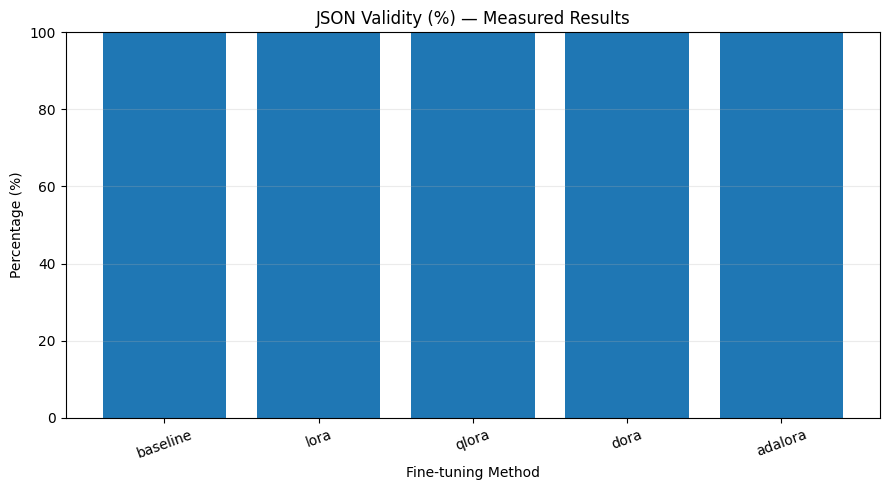

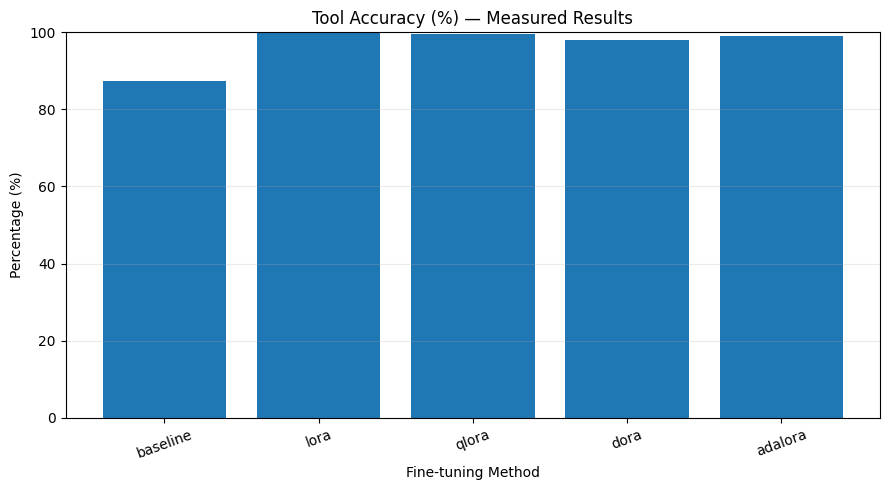

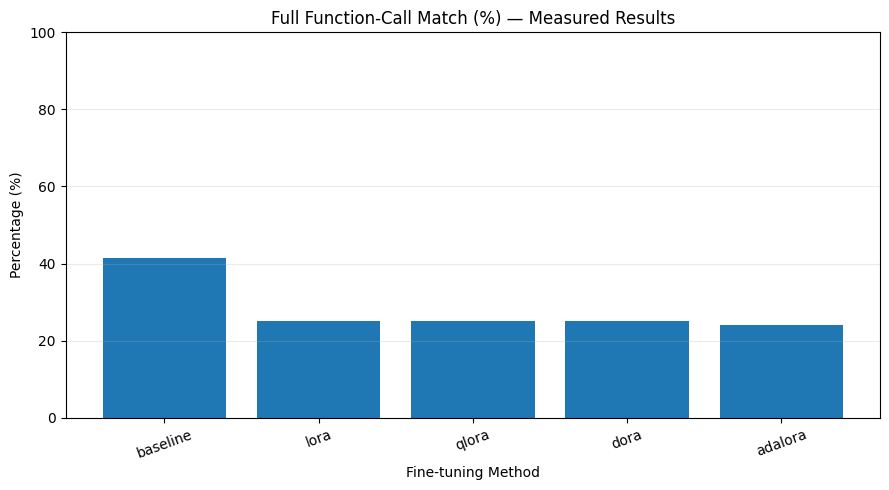

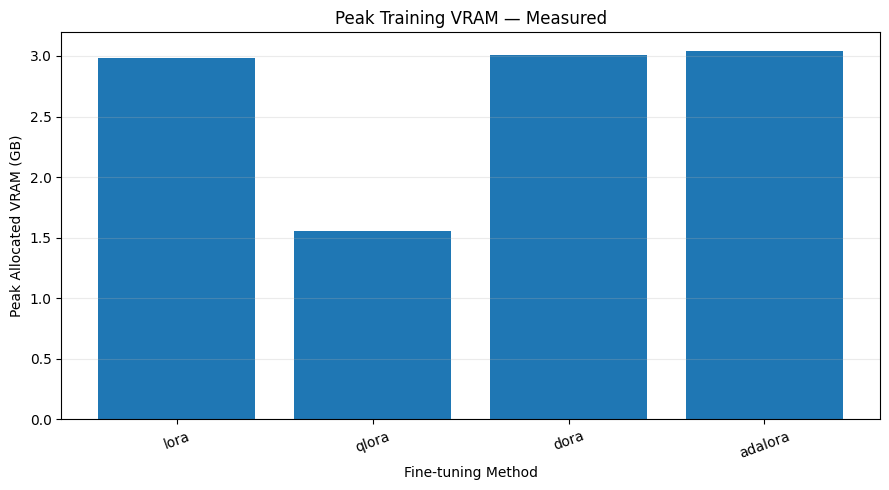

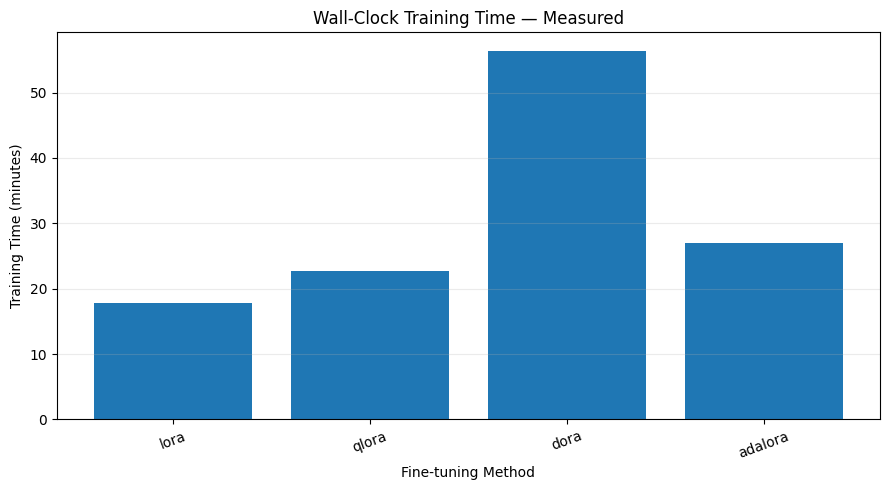


BEST PEFT METHOD (measured full-match priority)
Method: lora
JSON validity: 100.0 %
Tool accuracy: 100.0 %
Full match: 25.0 %
Peak training VRAM: 2.9863462448120117 GB
Training time: 17.83157618248333 minutes

Measured results exported to:
/content/Assignment_Beta_Question_no_2_23K0069_FINAL_WITH_SYNTHETIC_FALLBACK/measured_metrics_comparison.csv

Only completed experiment measurements are reported.
Missing measurements remain NaN; no estimated scores are inserted.


In [ ]:
# ============================================================
# MEASURED EXPERIMENT COMPARISON — ALL FIVE METHODS
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Ensure experiments have actually completed
if "results_df" not in globals() or results_df.empty:
    raise RuntimeError("Run the baseline and PEFT experiments first.")

# Required measured metrics
required_columns = [
    "method",
    "json_validity_pct",
    "tool_accuracy_pct",
    "full_match_pct",
    "peak_training_vram_gb",
    "training_minutes",
]

missing = [c for c in required_columns if c not in results_df.columns]
if missing:
    raise RuntimeError(f"Missing measured metrics: {missing}")

# Keep only actual experiment results
comparison = results_df.copy()

# Include available measured metadata
optional_columns = [
    "data_source",
    "test_examples",
    "schema_validity_pct",
    "peak_training_reserved_gb",
    "peak_eval_vram_gb",
    "train_loss",
    "trainable_parameters",
    "trainable_percentage_of_base_reference",
    "rank",
]

selected_columns = required_columns + [
    c for c in optional_columns if c in comparison.columns
]

comparison = comparison[selected_columns].copy()

# Ensure percentages and measurements are numeric
numeric_columns = [
    "json_validity_pct",
    "tool_accuracy_pct",
    "full_match_pct",
    "peak_training_vram_gb",
    "training_minutes",
]

for col in numeric_columns:
    comparison[col] = pd.to_numeric(
        comparison[col], errors="coerce"
    )

# Validate quality metrics
for col in [
    "json_validity_pct",
    "tool_accuracy_pct",
    "full_match_pct",
]:
    invalid = comparison[col].dropna().between(0, 100).all()
    assert invalid, f"Invalid percentage values in {col}"

# Display actual experimental data
print("=" * 75)
print("MEASURED EXPERIMENT RESULTS")
print("=" * 75)

print("Dataset source:", DATA_SOURCE_LABEL)
print("Synthetic fallback:", ACTIVE_DATA_SOURCE == "synthetic_fallback")

print("\nQUALITY METRICS (%)")
quality_table = comparison[
    ["method", "json_validity_pct",
     "tool_accuracy_pct", "full_match_pct"]
]

display(quality_table.round(2))

print("\nCOMPUTATIONAL EFFICIENCY")
efficiency_columns = [
    "method",
    "peak_training_vram_gb",
    "training_minutes",
]

if "peak_training_reserved_gb" in comparison.columns:
    efficiency_columns.append("peak_training_reserved_gb")

if "peak_eval_vram_gb" in comparison.columns:
    efficiency_columns.append("peak_eval_vram_gb")

display(comparison[efficiency_columns].round(3))

# ------------------------------------------------------------
# 1. QUALITY COMPARISON
# ------------------------------------------------------------

quality_metrics = {
    "json_validity_pct": "JSON Validity (%)",
    "tool_accuracy_pct": "Tool Accuracy (%)",
    "full_match_pct": "Full Function-Call Match (%)",
}

for metric, label in quality_metrics.items():
    plt.figure(figsize=(9, 5))

    plt.bar(
        comparison["method"],
        comparison[metric]
    )

    plt.title(label + " — Measured Results")
    plt.ylabel("Percentage (%)")
    plt.xlabel("Fine-tuning Method")
    plt.ylim(0, 100)
    plt.xticks(rotation=20)
    plt.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 2. PEAK TRAINING VRAM
# ------------------------------------------------------------

training_results = comparison.dropna(
    subset=["peak_training_vram_gb"]
)

if not training_results.empty:
    plt.figure(figsize=(9, 5))

    plt.bar(
        training_results["method"],
        training_results["peak_training_vram_gb"]
    )

    plt.title("Peak Training VRAM — Measured")
    plt.ylabel("Peak Allocated VRAM (GB)")
    plt.xlabel("Fine-tuning Method")
    plt.xticks(rotation=20)
    plt.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 3. WALL-CLOCK TRAINING TIME
# ------------------------------------------------------------

timed_results = comparison.dropna(
    subset=["training_minutes"]
)

if not timed_results.empty:
    plt.figure(figsize=(9, 5))

    plt.bar(
        timed_results["method"],
        timed_results["training_minutes"]
    )

    plt.title("Wall-Clock Training Time — Measured")
    plt.ylabel("Training Time (minutes)")
    plt.xlabel("Fine-tuning Method")
    plt.xticks(rotation=20)
    plt.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 4. BEST MEASURED PEFT METHOD
# ------------------------------------------------------------

peft_results = comparison[
    comparison["method"].isin(METHODS_TO_RUN)
].dropna(subset=["full_match_pct"])

if not peft_results.empty:
    best = peft_results.sort_values(
        [
            "full_match_pct",
            "json_validity_pct",
            "tool_accuracy_pct",
        ],
        ascending=False,
    ).iloc[0]

    print("\nBEST PEFT METHOD (measured full-match priority)")
    print("Method:", best["method"])
    print("JSON validity:", best["json_validity_pct"], "%")
    print("Tool accuracy:", best["tool_accuracy_pct"], "%")
    print("Full match:", best["full_match_pct"], "%")
    print("Peak training VRAM:", best["peak_training_vram_gb"], "GB")
    print("Training time:", best["training_minutes"], "minutes")

# ------------------------------------------------------------
# 5. EXPORT MEASURED RESULTS
# ------------------------------------------------------------

output_file = OUTPUT_DIR / "measured_metrics_comparison.csv"

comparison.to_csv(output_file, index=False)

print("\nMeasured results exported to:")
print(output_file)

print("\nOnly completed experiment measurements are reported.")
print("Missing measurements remain NaN; no estimated scores are inserted.")

## Historical synthetic smoke-test results (separate from the current run)

The earlier notebook run used 2,000 synthetic, template-generated examples. Its measured results were: baseline 52.5% exact match; LoRA 25.0%; QLoRA 25.0%; DoRA 25.0%; AdaLoRA 27.5%. These observations are retained only as historical debugging context. They are **not** Glaive results and must not be merged with the fresh source-derived results below. The previous protocol also had different code paths/dropout settings and did not run the rank sweep.

,method,json_validity_pct,tool_accuracy_pct,schema_validity_pct,full_match_pct,trainable_parameters,trainable_percentage_of_base_reference,peak_training_vram_gb,training_minutes,train_loss
0,baseline,100.0,87.5,99.0,41.5,0,0.000000,NaN,NaN,NaN
1,lora,100.0,100.0,25.0,25.0,2179072,0.141158,2.986346,17.831576,0.008105
2,qlora,100.0,99.5,25.0,25.0,2179072,0.141158,1.556646,22.664839,0.007157
3,dora,100.0,98.0,25.0,25.0,2279424,0.147658,3.004305,56.402461,0.007836
4,adalora,100.0,99.0,24.5,24.0,3270064,0.211831,3.042439,26.991904,0.981703


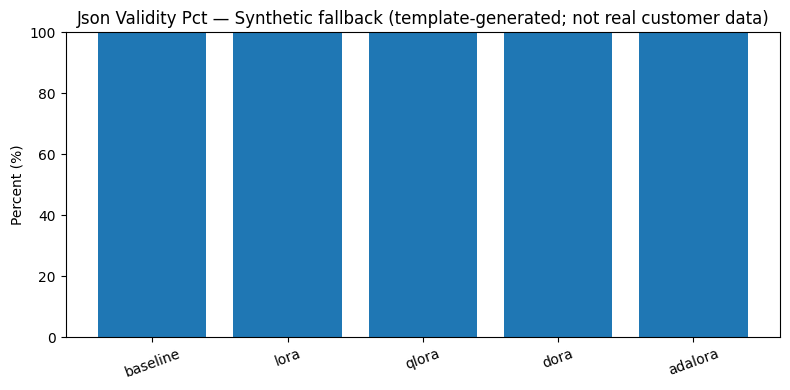

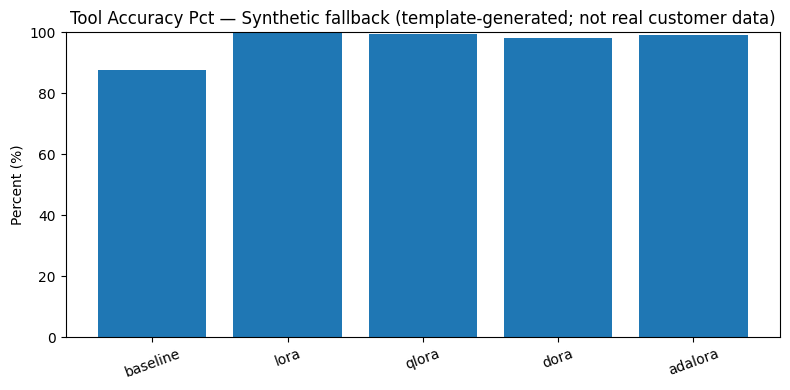

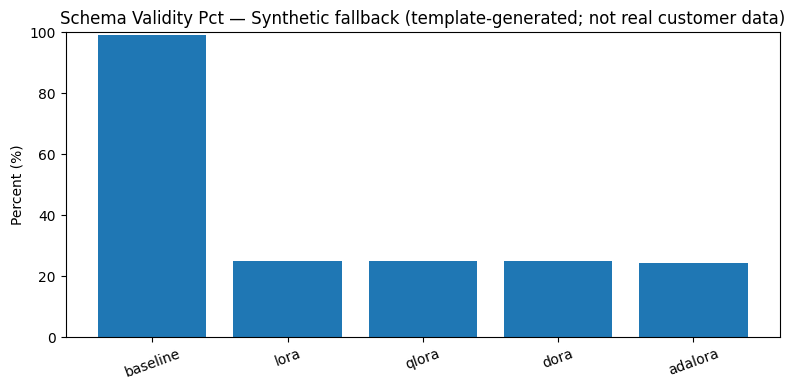

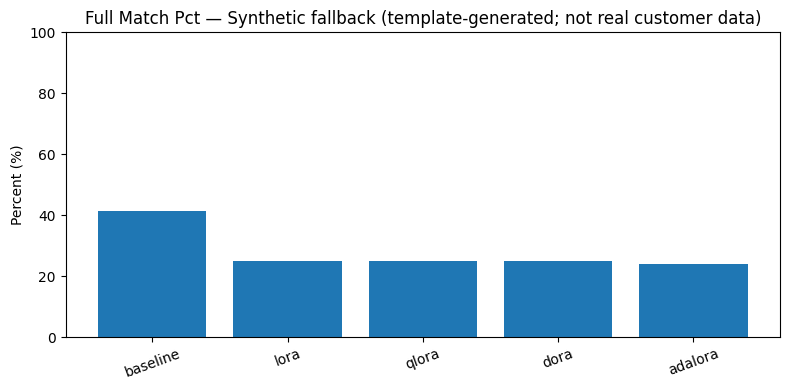

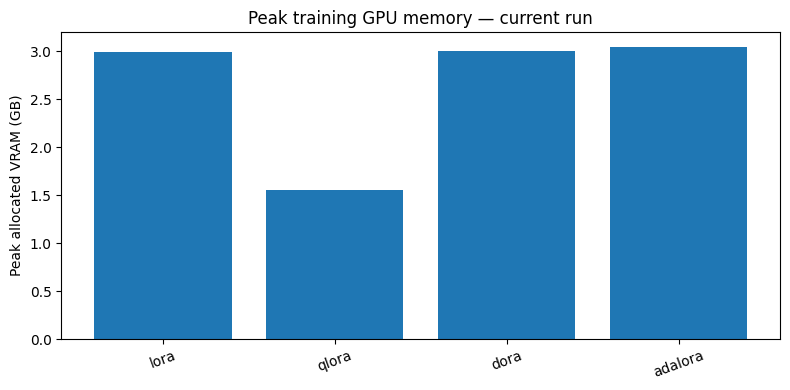

Best PEFT method selected for Section 3: lora
Best overall model selected for failure analysis: baseline
Selections are based on this new held-out run, not historical synthetic metrics.


In [ ]:
# Plot results from the source selected in the dataset manifest.
import matplotlib.pyplot as plt

if "results_df" not in globals() or results_df.empty:
    print("Run Section 2 before plotting the measured results.")
else:
    metric_cols = ["json_validity_pct", "tool_accuracy_pct", "schema_validity_pct", "full_match_pct"]
    display(results_df[[c for c in ["method"] + metric_cols + ["trainable_parameters", "trainable_percentage_of_base_reference", "peak_training_vram_gb", "training_minutes", "train_loss"] if c in results_df.columns]])
    for metric in metric_cols:
        plt.figure(figsize=(8, 4))
        plt.bar(results_df["method"], results_df[metric])
        plt.ylabel("Percent (%)")
        plt.title(f"{metric.replace('_', ' ').title()} — {DATA_SOURCE_LABEL}")
        plt.xticks(rotation=20)
        plt.ylim(0, 100)
        plt.tight_layout()
        plt.show()

    adapter_df = results_df[results_df["method"].isin(METHODS_TO_RUN)].dropna(subset=["peak_training_vram_gb"])
    if not adapter_df.empty:
        plt.figure(figsize=(8, 4))
        plt.bar(adapter_df["method"], adapter_df["peak_training_vram_gb"])
        plt.ylabel("Peak allocated VRAM (GB)")
        plt.title("Peak training GPU memory — current run")
        plt.xticks(rotation=20)
        plt.tight_layout()
        plt.show()

    # Select the best PEFT method on measured exact-match performance.
    peft_results = results_df[results_df["method"].isin(METHODS_TO_RUN)].copy()
    if peft_results.empty:
        raise RuntimeError("No PEFT results exist; cannot select the Section 3 method.")
    sort_cols = ["full_match_pct", "schema_validity_pct", "tool_accuracy_pct"]
    ascending = [False, False, False]
    if "training_minutes" in peft_results.columns:
        sort_cols.append("training_minutes")
        ascending.append(True)
    best_row = peft_results.sort_values(sort_cols, ascending=ascending).iloc[0]
    BEST_METHOD_FOR_RANK_SWEEP = str(best_row["method"])
    print("Best PEFT method selected for Section 3:", BEST_METHOD_FOR_RANK_SWEEP)

    # Section 4 failure analysis uses the best model overall, including baseline.
    overall_sort_cols = ["full_match_pct", "schema_validity_pct", "tool_accuracy_pct"]
    overall_ascending = [False, False, False]
    if "training_minutes" in results_df.columns:
        overall_sort_cols.append("training_minutes")
        overall_ascending.append(True)
    best_overall_row = results_df.sort_values(overall_sort_cols, ascending=overall_ascending).iloc[0]
    BEST_OVERALL_METHOD = str(best_overall_row["method"])
    print("Best overall model selected for failure analysis:", BEST_OVERALL_METHOD)
    print("Selections are based on this new held-out run, not historical synthetic metrics.")

## 10. Section 3 — rank sweep

After Section 2 finishes, the notebook selects the best PEFT method using the newly measured held-out exact-match score (schema validity, tool accuracy and training time break ties). It then trains that method at r=4, r=16 and r=32; the r=8 result is taken from Section 2.

### Rank-sweep interpretation

The chart is generated only after all three additional runs complete. Compare tool accuracy (as requested by the assignment) and exact-match accuracy; a larger rank is not automatically better. Do not write a conclusion until the graph and measured table are available.

\n=== LORA rank=4 ===
==((====))==  Unsloth 2026.11.4: Fast Qwen2 patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.14.1+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.8.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Tokenizer alignment verified — PAD='<|endoftext|>' (id=151643), EOS='<|im_end|>' (id=151645), vocab_size=151665
Unsloth: compiling each transformer block as one region (Qwen2DecoderLayer).
trainable params: 1,089,536 || all params: 1,544,803,840 || trainable%: 0.0705


The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None}.
==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 1,800 | Num Epochs = 3 | Total steps = 675
O^O/ \_/ \    Batch size per device = 1 | Gradient accumulation steps = 8
\        /    Data Parallel GPUs = 1 | Total batch size (1 x 8 x 1) = 8
 "-____-"     Trainable parameters = 1,089,536 of 1,544,803,840 (0.07% trained)


Step,Training Loss
10,0.402502
20,0.132196
30,0.011818
40,0.002265
50,0.000404
60,0.000196
70,0.000121
80,0.000049
90,0.000048
100,0.000042


Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene

... (52 outputs left out)

lora_rank_32: evaluated 175/200


Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene

lora_rank_32: evaluated 200/200


,method,data_source,json_valid_count,json_validity_pct,correct_tool_count,tool_accuracy_pct,schema_valid_count,schema_validity_pct,full_match_count,full_match_pct,...,trainable_percentage_of_loaded_representation,trainable_percentage_of_base_reference,rank,training_minutes,peak_training_vram_gb,train_loss,adapter_backend,peak_eval_vram_gb,epochs,peak_training_reserved_gb
0,lora_rank_4,synthetic_fallback,200,100.0,198,99.0,50,25.0,50,25.0,...,0.070529,0.070579,4,18.135061,2.970033,0.008153,Unsloth,NaN,NaN,NaN
3,lora,synthetic_fallback,200,100.0,200,100.0,50,25.0,50,25.0,...,0.140959,0.141158,8,17.831576,2.986346,0.008105,Unsloth,NaN,3.0,3.068359
1,lora_rank_16,synthetic_fallback,200,100.0,195,97.5,50,25.0,50,25.0,...,0.281521,0.282315,16,17.932821,3.018973,0.008126,Unsloth,NaN,NaN,NaN
2,lora_rank_32,synthetic_fallback,200,100.0,200,100.0,50,25.0,50,25.0,...,0.561461,0.564631,32,17.970656,3.084229,0.008174,Unsloth,NaN,NaN,NaN


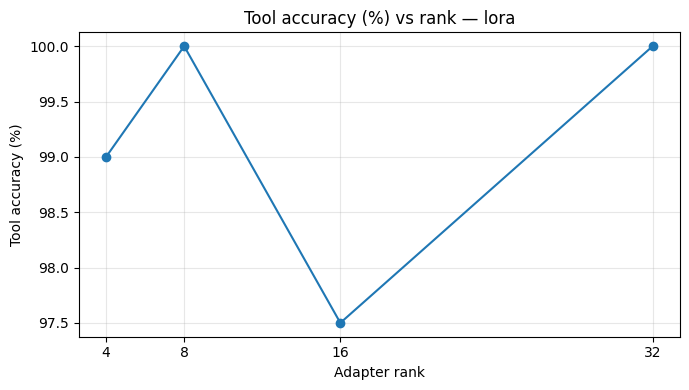

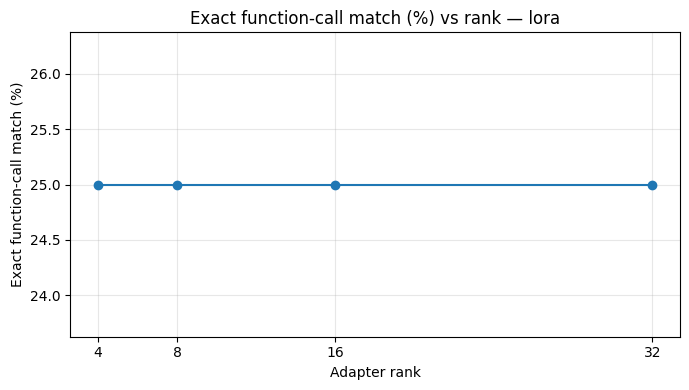

In [ ]:
def train_one_rank(method, rank):
    run_name = f"{method}_rank_{rank}"
    run_dir = OUTPUT_DIR / "rank_sweep" / run_name
    run_dir.mkdir(parents=True, exist_ok=True)

    # Start AdaLoRA above the target rank so the adaptive allocator has ranks to prune/reallocate.
    init_rank = max(12, rank + 4) if method == "adalora" else None
    model = build_model(method, rank=rank, adalora_init_rank=init_rank)
    param_stats = count_parameters(model)
    torch.cuda.empty_cache(); gc.collect()
    torch.cuda.reset_peak_memory_stats()
    start = time.perf_counter()

    trainer_cls = Trainer
    trainer = make_trainer(trainer_cls, model, run_dir, method=method)
    train_output = trainer.train()
    minutes = (time.perf_counter() - start) / 60
    peak_gb = torch.cuda.max_memory_allocated() / (1024**3)
    trainer.model.save_pretrained(run_dir / "adapter")
    tokenizer.save_pretrained(run_dir / "adapter")
    metrics, predictions = evaluate_model(trainer.model, test_rows, run_name)

    out = {
        **metrics,
        **param_stats,
        "rank": rank,
        "training_minutes": minutes,
        "peak_training_vram_gb": peak_gb,
        "train_loss": float(train_output.training_loss),
        "adapter_backend": "Unsloth" if method in UNSLOTH_OPTIMIZED_METHODS else "Hugging Face PEFT",
    }
    with open(run_dir / "metrics.json", "w", encoding="utf-8") as f:
        json.dump(out, f, ensure_ascii=False, indent=2)
    del trainer, model, predictions
    gc.collect(); torch.cuda.empty_cache()
    return out


if RUN_RANK_SWEEP:
    if BEST_METHOD_FOR_RANK_SWEEP not in METHODS_TO_RUN:
        raise ValueError("Best PEFT method was not selected. Complete the Section 2 comparison first.")
    sweep_results = []
    for rank in RANKS_TO_TEST:
        print(f"\\n=== {BEST_METHOD_FOR_RANK_SWEEP.upper()} rank={rank} ===")
        sweep_results.append(train_one_rank(BEST_METHOD_FOR_RANK_SWEEP, rank))

    rank8 = results_df[results_df["method"] == BEST_METHOD_FOR_RANK_SWEEP].iloc[0].to_dict()
    rank8["rank"] = 8
    sweep_results.append(rank8)
    rank_df = pd.DataFrame(sweep_results).sort_values("rank")
    rank_df.to_csv(OUTPUT_DIR / "section3_rank_sweep.csv", index=False)
    display(rank_df)

    for metric, ylabel in [("tool_accuracy_pct", "Tool accuracy (%)"), ("full_match_pct", "Exact function-call match (%)")]:
        plt.figure(figsize=(7, 4))
        plt.plot(rank_df["rank"], rank_df[metric], marker="o")
        plt.xlabel("Adapter rank")
        plt.ylabel(ylabel)
        plt.title(f"{ylabel} vs rank — {BEST_METHOD_FOR_RANK_SWEEP}")
        plt.xticks(sorted(rank_df["rank"].unique()))
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()

## 11. Section 4 — export five failure cases from the best overall model

The assignment asks for five held-out examples the best model got wrong. The cell below chooses the highest-scoring model overall (baseline included) from the fresh Section 2 results and exports observed failures only.

In [ ]:
if "BEST_OVERALL_METHOD" not in globals():
    raise RuntimeError("Complete Section 2 before exporting failure examples.")

FAILURE_RUN = BEST_OVERALL_METHOD
failure_file = OUTPUT_DIR / f"predictions_{FAILURE_RUN}.csv"
if not failure_file.exists():
    raise FileNotFoundError(f"Missing prediction file: {failure_file}")

pred = pd.read_csv(failure_file)
failures = pred[~pred["full_match"].astype(bool)].head(5).copy()
if len(failures) < 5:
    print(f"Only {len(failures)} incorrect examples were observed; exporting all available failures.")
columns = [
    "customer_message", "gold_tool", "gold_arguments", "raw_output",
    "json_valid", "predicted_tool", "predicted_arguments", "mistake_label"
]
display(failures[columns].to_string(index=False))
failures.to_csv(OUTPUT_DIR / f"five_failures_{FAILURE_RUN}.csv", index=False)
print(f"Exported {len(failures)} observed failures from {FAILURE_RUN}.")

'                                                                                              customer_message          gold_tool                                                                    gold_arguments                                                                                                              raw_output  json_valid    predicted_tool                                                           predicted_arguments           mistake_label\n   Please begin the return-and-refund process for order ORD011469: the product does not match the description.    initiate_refund {"order_id": "ORD011469", "reason": "the product does not match the description"} {"name": "initiate_refund", "arguments": {"order_id": "ORD011469", "reason": "product does not match the description"}}        True   initiate_refund {"order_id": "ORD011469", "reason": "product does not match the description"} argument value mismatch\n                                                   Where does order O

Exported 5 observed failures from baseline.


## 12. Multi-agent LoRA demonstration (parameter/storage comparison)

A shared frozen base with three task-specific LoRA adapters avoids storing three full copies of the base model. The code below is a parameter-count illustration for one adapted 4096 × 4096 matrix at rank 8; actual Qwen counts depend on the number and shapes of target modules.

In [ ]:
def lora_parameters_for_linear(in_features, out_features, rank):
    return rank * (in_features + out_features)

one_adapter = lora_parameters_for_linear(4096, 4096, rank=8)
three_adapters = 3 * one_adapter
full_layer_copy = 4096 * 4096

comparison = pd.DataFrame([
    {"design": "One shared base + 3 LoRA adapters", "additional_trainable_parameters_per_adapted_matrix": three_adapters},
    {"design": "Three independently fine-tuned copies (one layer each)", "additional_trainable_parameters_per_adapted_matrix": 3 * full_layer_copy},
])
display(comparison)


,design,additional_trainable_parameters_per_adapted_matrix
0,One shared base + 3 LoRA adapters,196608
1,Three independently fine-tuned copies (one lay...,50331648


## 12. Section 4 — production decision and discussion

### 12.1 Production decision

Do not select a model from historical synthetic results. Use the freshly measured test results from the selected dataset in `section2_results.csv`. The production candidate should be chosen using exact function-call match first, then schema validity and tool accuracy, while considering training VRAM, training time and the exact inference artifact intended for deployment.

A method with excellent JSON validity but weak argument accuracy is not production-ready: a backend tool call must satisfy the complete argument schema. QLoRA is a memory-efficiency option because it stores frozen base weights in 4-bit NF4, but memory savings alone do not prove better quality. Test the exact quantized/unquantized and merged/unmerged artifact you intend to serve.

### 12.2 Where it still breaks

Use the exported `five_failures_<best_method>.csv`. Label each observed error: wrong tool, unauthorized tool, invalid JSON/extra text, missing/extra argument, or wrong argument value. Look for repeated patterns such as missing order IDs, extra keys, confusion between order status and shipment tracking, or refund requests without explicit refund intent.

### 12.3 The agentic angle

A router agent, refund agent and shipping agent can share one frozen base model and use small task-specific LoRA adapters rather than storing three separately fine-tuned base models. The parameter illustration below compares one 4096×4096 matrix; it is not a whole-model storage measurement. A live adapter-swap risk is session inconsistency: one conversation can accidentally mix tool schemas or policies. Pin an adapter version per session, log it, validate rollouts, and maintain rollback.

### 12.4 What surprised me

Complete this paragraph from the fresh results: identify the largest gap between tool accuracy and exact match; compare the baseline with adapters; and name the method that achieved the best exact-match score. Avoid claiming that a method is superior when the differences are only a few examples or within run-to-run variation.

### 12.5 Experimental limitations

1. If the Glaive branch is selected, Glaive V2 is a public function-calling dataset, not verified production e-commerce logs; only semantically and schema-compatible source examples are retained.
2. If the synthetic fallback branch is selected, the experiment is a pipeline smoke test on generated templates, not evidence of generalization to real customers and not a substitute for the instructor-requested public function-calling dataset. Disclose this in the submission.
3. The canonical four-function schema is narrower than the original Glaive schemas. Only source examples with compatible tool semantics and arguments are retained.
4. The single 200-example held-out set gives a useful assignment comparison but limited statistical precision. A stronger study would repeat training with multiple random seeds and report mean ± standard deviation.
5. BFCL is an independent external benchmark and is not required for the core custom evaluation. No BFCL result should be reported until this model checkpoint is actually evaluated.
6. AdaLoRA can change active ranks during training. Record the PEFT version and verify the saved adapter can be reloaded before making a deployment claim.

## 13. Optional independent evaluation: Berkeley Function-Calling Leaderboard (BFCL)

BFCL provides a broader independent tool-calling evaluation with function selection, argument correctness, multiple/parallel calls, relevance/irrelevance and multi-turn/agentic categories depending on the BFCL version. Its current leaderboard/repository evolves; record the exact package version or Git commit, categories, backend and checkpoint used.

**Do not use BFCL as training data or replace the assignment's 200-example e-commerce test with it.** BFCL score definitions and test distributions differ from the custom exact-match metric, so report them separately.

The BFCL repository provides a CLI that separates response generation from grading. Check the official README and `SUPPORTED_MODELS.md` for the exact CLI flags and local-model backend supported by the version you install. For a custom fine-tuned Qwen checkpoint, use a supported local inference backend and confirm the model handler supports the checkpoint format. If adapter loading is not supported, merge a copy of the adapter into a base-model copy, reload it, and evaluate that exact merged artifact. Never overwrite the only adapter checkpoint.

Official resources:

- Leaderboard: https://gorilla.cs.berkeley.edu/leaderboard.html
- Repository / current usage instructions: https://github.com/ShishirPatil/gorilla/tree/main/berkeley-function-call-leaderboard
- BFCL research paper: https://proceedings.mlr.press/v267/patil25a.html

The next cell is a reporting template only. It deliberately contains no fabricated scores.

In [ ]:
# BFCL results template only. Populate only after running the official evaluator on these checkpoints.
BFCL_RESULTS_TEMPLATE = pd.DataFrame([
    {"model": name, "categories": "not run", "score": np.nan,
     "backend": "not run", "bfcl_version_or_commit": "not recorded", "checkpoint": "not run"}
    for name in ["base", "lora", "qlora", "dora", "adalora"]
])
display(BFCL_RESULTS_TEMPLATE)
print("No BFCL score is claimed until the official generation and evaluation steps are run.")

,model,categories,score,backend,bfcl_version_or_commit,checkpoint
0,base,not run,NaN,not run,not recorded,not run
1,lora,not run,NaN,not run,not recorded,not run
2,qlora,not run,NaN,not run,not recorded,not run
3,dora,not run,NaN,not run,not recorded,not run
4,adalora,not run,NaN,not run,not recorded,not run


No BFCL score is claimed until the official generation and evaluation steps are run.


## 14. Export all results

The output folder contains the source audit, selected source-derived examples, exact split, model checkpoints, per-example predictions, measured results, rank-sweep results, and failure analysis. The next cell creates a ZIP and starts a Colab download.

In [ ]:
import shutil

zip_path = shutil.make_archive(str(OUTPUT_DIR), "zip", root_dir=OUTPUT_DIR)
print("Created:", zip_path)

try:
    from google.colab import files
    files.download(zip_path)
except Exception:
    print("Outside Colab. Download the ZIP from the notebook file browser:", zip_path)


Created: /content/Assignment_Beta_Question_no_2_23K0069_FINAL_WITH_SYNTHETIC_FALLBACK.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### References

- Assignment Beta, Question 2, Sections 1–4 (course handout, Fall 2026).
- Glaive AI, *Glaive Function Calling V2* dataset card: https://huggingface.co/datasets/glaiveai/glaive-function-calling-v2 (accessed 11 November 2026).
- Hugging Face Datasets documentation: https://huggingface.co/docs/datasets/stream.
- Hugging Face PEFT AdaLoRA documentation: https://huggingface.co/docs/peft/main/package_reference/adalora.
- Hugging Face Transformers PEFT guide: https://huggingface.co/docs/transformers/peft.
- Qwen, *Qwen2.5-1.5B-Instruct* model card: https://huggingface.co/Qwen/Qwen2.5-1.5B-Instruct.
- Berkeley Function-Calling Leaderboard (BFCL), official leaderboard: https://gorilla.cs.berkeley.edu/leaderboard.html.
- BFCL repository and current evaluation instructions: https://github.com/ShishirPatil/gorilla/tree/main/berkeley-function-call-leaderboard.
- Patil et al., *The Berkeley Function Calling Leaderboard (BFCL): From Tool Use to Agentic Evaluation of Large Language Models*, ICML 2025: https://proceedings.mlr.press/v267/patil25a.html.
- Unsloth documentation — installation and FastLanguageModel adapter API: https://unsloth.ai/docs/get-started/install/pip-install and https://unsloth.ai/docs/get-started/install/google-colab.

- Unsloth, Google Colab installation and FastLanguageModel usage: https://unsloth.ai/docs/get-started/install/google-colab (accessed 11 November 2026).
- Unsloth CLI implementation showing `FastLanguageModel.get_peft_model(..., use_dora=...)`: https://github.com/unslothai/unsloth/blob/main/unsloth-cli.py (accessed 11 November 2026).
- Hugging Face PEFT, AdaLoRA API and `update_and_allocate()` requirement: https://huggingface.co/docs/peft/main/package_reference/adalora (accessed 11 November 2026).

- Unsloth official pip installation documentation: https://unsloth.ai/docs/get-started/install/pip-install (accessed 11 November 2026).
- Unsloth GPU requirements (Tesla T4 / compute capability 7.0+): https://unsloth.ai/docs/get-started/fine-tuning-for-beginners/unsloth-requirements (accessed 11 November 2026).


## Submission declaration and provenance

- **AI assistance:** ChatGPT was used to improve notebook organization, implement transparent dataset filtering/validation, and review the experimental methodology.
- **Dataset source:** The notebook first attempts `glaiveai/glaive-function-calling-v2`. If 2,000 unique compatible examples cannot be curated, it automatically uses a separately labelled synthetic fallback. The actual run source and fallback reason are recorded in `dataset_manifest.json`. Synthetic fallback is not Glaive data or verified production e-commerce traffic.
- **Data preparation:** robust JSON/Python-literal parsing; conservative exact-alias/semantic mapping; argument-schema validation; deduplication; deterministic selection; stratified 1,800/200 split. Synthetic fallback, when activated, is separately generated and provenance-labelled.
- **Base model:** `Qwen/Qwen2.5-1.5B-Instruct`.
- **Methods:** baseline, LoRA, QLoRA (4-bit NF4), DoRA, AdaLoRA.
- **Hardware:** detected and recorded in the runtime cell; no GPU details are hard-coded into final experimental results.
- **Random seed:** 42.
- **External benchmark:** BFCL instructions and results template are included; scores remain blank until an actual evaluation is run.
- **Reproducibility artifacts:** source audit, selected dataset JSONL/JSON, exact train/test splits, adapter checkpoints, per-example predictions, metrics, rank-sweep results, failure export, and result ZIP are saved to the output folder.

Only figures produced by a completed run should be submitted as experimental measurements. The historical synthetic run is explicitly separated and is not presented as the final real-source result.